# Simulations for *Mutual information in linear recurrent circuits: inhibition in the olfactory bulb increases information only against a fixed noise floor*

Vijay Singh and Martin Tchernookov.

This notebook reproduces every figure and every number reported in the manuscript and
its supporting information (S1 Text). It runs top to bottom with no arguments, and it prints, beside each
computed value, the value quoted in the paper, so that a mismatch is visible immediately
rather than requiring a manual audit.

| output | file | where it appears |
|---|---|---|
| Fig 1 | `figures/Fig1_framework.pdf` | main text, the framework |
| Fig 2 | `figures/Fig2_two_noise_models.pdf` | main text, the two noise models compared |
| Fig 3 | `figures/Fig4_gradient_ascent.pdf` | main text, matched wiring is found by optimization |
| Fig 4 | `figures/Fig5_chow_network.pdf` | main text, the analysis on Chow et al.'s network |
| Appendix figure | `figures/Fig3_flatness.pdf` | appendix, accuracy of the spectral-flatness identity |
| `results.json` | machine-readable dump of every recorded quantity | used to fill and audit the manuscript |

**Data.** One data file is used: `data/chow2012_stimuli.npz`, the eight glomerular
activation patterns of Chow, Wick & Riecke (2012), recovered from their published figures.
`chow_model.py` is the engine of our reproduction of that paper and simulates their
neurogenesis rule; it is used only in section 9. Everything else is synthetic.

## 0. Dependencies and conventions

In [1]:
import os, json, time, platform
import numpy as np
import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import solve_continuous_lyapunov

print("python     ", platform.python_version())
print("numpy      ", np.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", mpl.__version__)
print()
print("All results below are computed in closed form or by an exact linear solve, with the")
print("single exception of the Monte-Carlo validation in section 2, which is stochastic by")
print("design and is seeded. Quantities that depend on an average over random connectivity")
print("seeds are reported with the seed count and the standard error of that average.")

python      3.11.15
numpy       2.4.4
scipy       1.17.1
matplotlib  3.10.9

All results below are computed in closed form or by an exact linear solve, with the
single exception of the Monte-Carlo validation in section 2, which is stochastic by
design and is seeded. Quantities that depend on an average over random connectivity
seeds are reported with the seed count and the standard error of that average.


### Shared figure style and the audit machinery

Cosmetic settings plus two helpers used throughout: `check`, which prints every computed quantity beside the value quoted in the paper, and `record`, which collects them all into `results.json` at the end.

In [2]:
OUTDIR = "figures"
os.makedirs(OUTDIR, exist_ok=True)

FULL_W = 7.2                       # authoring width for a width=\textwidth figure
# Figs 3 and 4 are single rows of four panels, typeset across the manuscript's left margin
# with the PLOS adjustwidth idiom: text width 5.25in plus 2.25in taken from that margin.
# WIDE_W must match the \includegraphics width used for them in manuscript_template.tex.
WIDE_W, WIDE_H = 7.5, 2.30

def fig_width(frac=1.0):
    return FULL_W * frac

# Colours are assigned by meaning, not by figure, so the same condition wears the same
# colour throughout: red is the matched / theoretical target, grey is the unstructured
# control, blue is the quantity the paper is actually tracking, green is a fourth series.
C_MAIN   = "#2166ac"
C_TARGET = "#b2182b"
C_CTRL   = "#8c8c8c"
C_ALT    = "#1b7837"
C_INK    = "#333333"
C_FAINT  = "#c3ced9"
SEQ_CMAP = "Blues"

def seq_cmap(lo=0.25, hi=1.0):
    base = plt.get_cmap(SEQ_CMAP)
    return mpl.colors.LinearSegmentedColormap.from_list(
        "seq_trunc", base(np.linspace(lo, hi, 256)))

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8.0, "axes.labelsize": 8.5, "axes.titlesize": 9.0,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.0,
    "mathtext.fontset": "stixsans",
    "lines.linewidth": 1.5, "lines.markersize": 3.5, "lines.markeredgewidth": 0.0,
    "patch.linewidth": 0.6,
    "axes.linewidth": 0.7, "axes.edgecolor": "#8a8a8a", "axes.labelcolor": "#222222",
    "axes.titlepad": 6.0, "axes.titleweight": "normal",
    "axes.spines.top": True, "axes.spines.right": True,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "grid.alpha": 1.0,
    "xtick.color": "#4a4a4a", "ytick.color": "#4a4a4a",
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "legend.frameon": False, "legend.handlelength": 1.6,
    "legend.handletextpad": 0.5, "legend.labelspacing": 0.35,
    # embed TrueType rather than Type 3 fonts, which some journals reject
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "figure.dpi": 110, "savefig.dpi": 400, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})

def panel(ax, label, dx=-30, dy=8):
    ax.annotate(label, xy=(0, 1), xycoords="axes fraction",
                xytext=(dx, dy), textcoords="offset points",
                fontsize=9.5, fontweight="bold", va="bottom", ha="left",
                color="#111111", annotation_clip=False)

def panels(axes, labels="abcdefgh", **kw):
    for ax, lab in zip(np.ravel(np.asarray(axes, dtype=object)), labels):
        panel(ax, lab, **kw)

def save(fig, name):
    """Write a vector PDF (the file the manuscript includes) and a PNG preview."""
    pdf_path = os.path.join(OUTDIR, os.path.splitext(name)[0] + ".pdf")
    png_path = os.path.join(OUTDIR, os.path.splitext(name)[0] + ".png")
    fig.savefig(pdf_path); fig.savefig(png_path)
    w, h = fig.get_size_inches()
    print(f"  -> {pdf_path}   ({w:.2f} x {h:.2f} in)")
    return pdf_path

# ---------------------------------------------------------------- audit machinery
RESULTS = {}
CHECKS = []          # (label, computed, quoted, passed) for every check() call
FAILURES = []

def record(key, value):
    """Store a quantity for the machine-readable audit dump at the end."""
    RESULTS[key] = float(value)
    return value

def check(label, got, want, tol=0.02, fmt="{:.3f}", key=None):
    """Compare a computed value against the value printed in the manuscript.

    Every call is logged. The manifest cell at the end of the notebook raises if any
    comparison failed, so a mismatch stops the run rather than scrolling past."""
    got = float(got)
    if key is None:
        key = label
    record(key, got)
    if want is None or (isinstance(want, float) and np.isnan(want)):
        CHECKS.append((label, got, None, None))
        print(f"  [--- ] {label:<50s} computed {fmt.format(got):>11s}   (no reference yet)")
        return got
    passed = abs(got - want) <= tol * max(1.0, abs(want))
    CHECKS.append((label, got, want, passed))
    if not passed:
        FAILURES.append(f"{label}: computed {got!r}, manuscript {want!r}")
    print(f"  [{'OK  ' if passed else 'DIFF'}] {label:<50s} computed {fmt.format(got):>11s}   "
          f"manuscript {fmt.format(want):>11s}")
    return got

def show_table(rows, header, title=None):
    widths = [max(len(str(header[i])), *(len(str(r[i])) for r in rows)) + 2
              for i in range(len(header))]
    line = "".join(str(h).ljust(w) for h, w in zip(header, widths)).rstrip()
    if title:
        print(title); print("=" * len(line))
    print(line); print("-" * len(line))
    for r in rows:
        print("".join(str(c).ljust(w) for c, w in zip(r, widths)).rstrip())

# a relative path, so the saved output does not carry whatever absolute path the
# notebook happened to be run from
print("style applied; figures ->", os.path.relpath(OUTDIR))

style applied; figures -> figures


## 1. The world, the two mutual-information formulas, and the odor ensemble

Everything below is built on one network and one stimulus ensemble, defined once here.

**The network.** $N_m = 50$ mitral cells and $N_g = 200$ granule cells coupled through
reciprocal dendrodendritic synapses, so that the effective mitral-to-mitral coupling is
$\mathbf W_{\mathrm{eff}} = \mathbf I + w\,\mathbf W^{(gm)\top}\mathbf W^{(gm)}$. A granule
cell is a binary row of $\mathbf W^{(gm)}$ carrying $n_{\mathrm{connect}}$ unit entries. In
*random* wiring those targets are drawn uniformly from all mitral cells; in
*source-matched* wiring they are drawn from a single odor-source block.

**The stimulus.** A block-structured covariance $\Sigma_c$ standing for five odor sources:
each source occupies a block of ten glomeruli with within-block correlation $0.6$ and unit
variance, on top of a background variance $0.2$ shared by every cell. Two glomeruli are
correlated if and only if they are driven by the same source.

**The two noise conventions.** Model A places the noise inside the recurrent loop, so the
recurrence filters it exactly as it filters the signal, and the Lyapunov solution for
symmetric $\mathbf W_{\mathrm{eff}}$ is $\Sigma_{r\mid c} = \tfrac{\sigma^2}{2}\mathbf
W_{\mathrm{eff}}^{-1}$. Model B places the noise downstream at a readout and holds total
output power at the feedforward level $P = \operatorname{Tr}\Sigma_c$ with a compensating
gain $g$. The two give opposite verdicts on recurrent inhibition, which is the dichotomy
the paper is organized around.

**Spectral flatness.** $\mathcal F(\Sigma) = (\det\Sigma)^{1/N} / (\operatorname{Tr}\Sigma/N)$,
the ratio of the geometric to the arithmetic mean of the eigenvalues, equal to one exactly
when the spectrum is white. It is defined here and used in section 5.

In [3]:
# ---------------------------------------------------------------- world
N_m, n_blocks = 50, 5
block_corr, within_var, background_var = 0.6, 1.0, 0.2
sigma_noise = 0.1                       # readout noise sigma_out, and the in-loop sigma
blocks = np.repeat(np.arange(n_blocks), N_m // n_blocks)
SEED = 1234

def generate_odor_covariance(N=N_m, nb=n_blocks, corr=block_corr,
                             var=within_var, bg=background_var):
    """Block covariance: each block is one correlated odor source."""
    bs = N // nb
    Sig = bg * np.eye(N)
    for b in range(nb):
        lo, hi = b * bs, min((b + 1) * bs, N)
        blk = np.full((hi - lo, hi - lo), var * corr)
        np.fill_diagonal(blk, var)
        Sig[lo:hi, lo:hi] += blk
    return Sig

Sigma_c = generate_odor_covariance()
power_budget = np.trace(Sigma_c)

within_pair = Sigma_c[0, 1]
across_pair = Sigma_c[0, N_m // n_blocks]
assert np.isclose(within_pair, block_corr) and np.isclose(across_pair, 0.0)
print(f"block covariance: within-block {within_pair:.2f}, cross-block {across_pair:.2f}, "
      f"diagonal {Sigma_c[0,0]:.2f}")

# ---------------------------------------------------------------- the two MI formulas
def mi_inloop(Sigma_c, W_eff, sigma):
    """Model A: noise inside the recurrent loop."""
    n = W_eff.shape[0]
    return 0.5 * np.linalg.slogdet(
        np.eye(n) + (2.0 / sigma**2) * np.linalg.solve(W_eff, Sigma_c))[1]

def output_covariance(Sigma_c, W_eff):
    """C_w = W_eff^{-1} Sigma_c W_eff^{-T}, the output signal covariance before the gain."""
    F = np.linalg.inv(W_eff)
    return F @ Sigma_c @ F.T

def mi_budget(Sigma_c, W_eff, sigma, budget=None):
    """Model B: readout noise downstream of the filter, plus a fixed activity budget."""
    C = output_covariance(Sigma_c, W_eff)
    P = np.trace(Sigma_c) if budget is None else budget
    g2 = P / np.trace(C)
    return 0.5 * np.linalg.slogdet(np.eye(W_eff.shape[0]) + g2 * C / sigma**2)[1]

def W_eff_from(W_gm, w):
    return np.eye(W_gm.shape[1]) + w * (W_gm.T @ W_gm)

def spectral_flatness(Sig):
    """F(Sigma) = geometric mean / arithmetic mean of the eigenvalues; 1 iff white."""
    ev = np.linalg.eigvalsh(Sig)
    ev = np.maximum(ev, 1e-300)
    return float(np.exp(np.mean(np.log(ev))) / np.mean(ev))

def block_purity(W_gm, blk=blocks):
    """For each granule cell, the largest fraction of its targets falling in one block,
    averaged over cells with at least one target."""
    n_b = int(blk.max()) + 1
    pur = [max(W_gm[j][blk == b].sum() for b in range(n_b)) / W_gm[j].sum()
           for j in range(W_gm.shape[0]) if W_gm[j].sum() > 0]
    return float(np.mean(pur)) if pur else np.nan

# ---------------------------------------------------------------- wiring
def make_wiring(N_m_, N_g_, n_connect, kind, blk=None, seed=0):
    """Binary granule-to-mitral connectivity. 'random' draws targets uniformly;
    'matched' draws every target of a given granule cell from one odor-source block."""
    rng = np.random.default_rng(seed)
    W = np.zeros((N_g_, N_m_))
    if kind == "matched":
        n_b = int(blk.max()) + 1
        for j in range(N_g_):
            pool = np.where(blk == rng.integers(n_b))[0]
            W[j, rng.choice(pool, min(n_connect, len(pool)), replace=False)] = 1.0
    else:
        for j in range(N_g_):
            W[j, rng.choice(N_m_, n_connect, replace=False)] = 1.0
    return W

# ---------------------------------------------------------------- odor ensemble
N_ODORS = 200                # up from the 40 used in earlier drafts
rng_ens = np.random.default_rng(7)
sources = np.zeros((n_blocks, N_m))
for b in range(n_blocks):
    pool = np.where(blocks == b)[0]
    sources[b, pool] = 1.0 + 0.4 * rng_ens.random(len(pool))

odors = np.zeros((N_m, N_ODORS))
odor_source = np.zeros(N_ODORS, dtype=int)
for k in range(N_ODORS):
    b = int(rng_ens.integers(n_blocks))
    odor_source[k] = b
    mix = 0.15 * rng_ens.random(n_blocks)
    mix[b] = 1.0
    odors[:, k] = np.maximum(sources.T @ mix + 0.1 * rng_ens.standard_normal(N_m), 0)

pairs = np.triu_indices(N_ODORS, k=1)
same_src = (odor_source[:, None] == odor_source[None, :])[pairs]
r_in_same = float(np.corrcoef(odors.T)[pairs][same_src].mean())

I_ff = mi_budget(Sigma_c, np.eye(N_m), sigma_noise, power_budget)
F_in = spectral_flatness(Sigma_c)

print(f"power budget P = tr(Sigma_c) = {power_budget:.1f}")
print(f"{N_ODORS} odors drawn from {n_blocks} sources")
print()
check("same-source input correlation", r_in_same, 0.9583935735529217, fmt="{:.3f}",
      key="r_in_same")
check("feedforward MI I(0), nats", I_ff, 108.72904654352867, fmt="{:.3f}", key="I_ff")
check("input spectral flatness F(Sigma_c)", F_in, 0.6354908076050703, fmt="{:.4f}", key="F_in")
pearson_within = float(Sigma_c[0, 1] / Sigma_c[0, 0])
print(f"within-source Pearson correlation of Sigma_c = {pearson_within:.2f} "
      f"(covariance {Sigma_c[0,1]:.2f} over variance {Sigma_c[0,0]:.2f})")
check("within-source Pearson correlation", pearson_within, 0.5, fmt="{:.3f}",
      key="pearson_within")
record("sigma_c_diag", Sigma_c[0, 0])
for k_, v_ in (("P_budget", power_budget), ("N_ODORS", N_ODORS), ("N_m", N_m),
               ("n_blocks", n_blocks), ("sigma_out", sigma_noise),
               ("block_size", N_m // n_blocks)):
    record(k_, v_)

block covariance: within-block 0.60, cross-block 0.00, diagonal 1.20
power budget P = tr(Sigma_c) = 60.0
200 odors drawn from 5 sources

  [OK  ] same-source input correlation                      computed       0.958   manuscript       0.958
  [OK  ] feedforward MI I(0), nats                          computed     108.729   manuscript     108.729
  [OK  ] input spectral flatness F(Sigma_c)                 computed      0.6355   manuscript      0.6355
within-source Pearson correlation of Sigma_c = 0.50 (covariance 0.60 over variance 1.20)
  [OK  ] within-source Pearson correlation                  computed       0.500   manuscript       0.500


## 2. Monte-Carlo validation of the closed-form mutual information

Every number in this paper comes from a determinant rather than from a simulation, so the
determinant had better be right. This section checks it directly. We integrate the
stochastic dynamics

$$d\mathbf r = (\mathbf W\mathbf r + \mathbf S\mathbf c)\,dt + \Sigma_\eta^{1/2}\,d\mathbf B_t$$

for a small network with the Euler-Maruyama scheme, collect the stationary response over
many trials and many stimuli, and compare three things against theory: the conditional
covariance against the Lyapunov solution, the marginal covariance against the law of total
covariance, and the mutual information estimated from the two sampled covariances against
the closed form. The test is run on a small network, $N = 8$, so that the sampled
covariances converge at a tractable number of trials.

This is the only stochastic computation in the notebook.

In [4]:
def simulate_ou(W, S, Sigma_eta, c, dt, n_steps, n_trials, burn, rng):
    """Euler-Maruyama integration of dr = (W r + S c) dt + Sigma_eta^{1/2} dB,
    returning the stationary samples after a burn-in. One fixed stimulus c."""
    N = W.shape[0]
    L = np.linalg.cholesky(Sigma_eta)
    r = np.zeros((n_trials, N))
    drive = (S @ c)[None, :]
    out = np.empty((n_trials, n_steps - burn, N))
    sq = np.sqrt(dt)
    for t in range(n_steps):
        noise = rng.standard_normal((n_trials, N)) @ L.T
        r = r + dt * (r @ W.T + drive) + sq * noise
        if t >= burn:
            out[:, t - burn, :] = r
    return out

# ---- a small, generic, non-symmetric test network
rng_mc = np.random.default_rng(SEED)
N_mc, M_mc = 8, 4
W_mc = -np.eye(N_mc) + 0.25 * rng_mc.standard_normal((N_mc, N_mc))
W_mc -= np.eye(N_mc) * max(0.0, 0.05 + np.max(np.linalg.eigvals(W_mc).real))
S_mc = rng_mc.standard_normal((N_mc, M_mc)) / np.sqrt(M_mc)
A_mc = rng_mc.standard_normal((M_mc, M_mc))
Sigma_c_mc = A_mc @ A_mc.T / M_mc + 0.2 * np.eye(M_mc)
B_mc = rng_mc.standard_normal((N_mc, N_mc))
Sigma_eta_mc = 0.3 * (B_mc @ B_mc.T / N_mc + np.eye(N_mc))

assert np.max(np.linalg.eigvals(W_mc).real) < 0, "test network must be stable"

# ---- theory
Src_theory = solve_continuous_lyapunov(W_mc, -Sigma_eta_mc)
Winv_S = np.linalg.solve(W_mc, S_mc)
Sr_theory = Src_theory + Winv_S @ Sigma_c_mc @ Winv_S.T
I_theory = 0.5 * (np.linalg.slogdet(Sr_theory)[1] - np.linalg.slogdet(Src_theory)[1])

# ---- Monte Carlo
dt_mc, n_steps_mc, burn_mc, n_trials_mc, n_stim_mc = 0.004, 3000, 1500, 300, 1200
t0 = time.time()
cs = rng_mc.multivariate_normal(np.zeros(M_mc), Sigma_c_mc, size=n_stim_mc)
cond_cov = np.zeros((N_mc, N_mc))
means = np.empty((n_stim_mc, N_mc))
for k in range(n_stim_mc):
    samp = simulate_ou(W_mc, S_mc, Sigma_eta_mc, cs[k], dt_mc, n_steps_mc,
                       n_trials_mc, burn_mc, rng_mc)
    flat = samp.reshape(-1, N_mc)
    means[k] = flat.mean(0)
    cond_cov += np.cov(flat.T) / n_stim_mc
marg_cov = cond_cov + np.cov(means.T)
I_mc = 0.5 * (np.linalg.slogdet(marg_cov)[1] - np.linalg.slogdet(cond_cov)[1])
mc_secs = time.time() - t0

rel_cond = float(np.linalg.norm(cond_cov - Src_theory) / np.linalg.norm(Src_theory))
rel_marg = float(np.linalg.norm(marg_cov - Sr_theory) / np.linalg.norm(Sr_theory))
mean_err = float(np.max(np.abs(means - cs @ (-Winv_S).T).mean(0)))

print(f"Monte Carlo: {n_stim_mc} stimuli x {n_trials_mc} trials x "
      f"{n_steps_mc - burn_mc} retained steps, dt = {dt_mc}  ({mc_secs:.0f} s)")
print()
check("conditional covariance, relative error", rel_cond, 0.011926591353122098,
      tol=0.5, fmt="{:.4f}", key="mc_rel_cond")
check("marginal covariance, relative error", rel_marg, 0.03575361031973781,
      tol=0.5, fmt="{:.4f}", key="mc_rel_marg")
check("closed-form MI, nats", I_theory, 4.627324279663736, fmt="{:.4f}", key="mc_I_theory")
check("Monte-Carlo MI, nats", I_mc, 4.597994781033636, tol=0.05, fmt="{:.4f}", key="mc_I_mc")
check("MI discrepancy, nats", abs(I_mc - I_theory), 0.02932949863010048,
      tol=1.0, fmt="{:.4f}", key="mc_I_gap")
for k_, v_ in (("dt_mc", dt_mc), ("n_steps_mc", n_steps_mc), ("n_trials_mc", n_trials_mc),
               ("n_stim_mc", n_stim_mc), ("N_mc", N_mc), ("M_mc", M_mc)):
    record(k_, v_)

Monte Carlo: 1200 stimuli x 300 trials x 1500 retained steps, dt = 0.004  (308 s)

  [OK  ] conditional covariance, relative error             computed      0.0119   manuscript      0.0119
  [OK  ] marginal covariance, relative error                computed      0.0358   manuscript      0.0358
  [OK  ] closed-form MI, nats                               computed      4.6273   manuscript      4.6273
  [OK  ] Monte-Carlo MI, nats                               computed      4.5980   manuscript      4.5980
  [OK  ] MI discrepancy, nats                               computed      0.0293   manuscript      0.0293


## 3. Fig 1. The framework and its three limits

A schematic, drawn rather than computed. Panel (a) shows where the two noise conventions
inject their noise: Model A inside the recurrent loop, where the recurrence filters it
along with the signal, and Model B after the loop at a readout, where it does not. Panel
(b) shows the three published models the general formula contains, each as a setting of
the recurrent matrix, the sensitivity matrix, and the two dimensions.

  -> figures/Fig1_framework.pdf   (7.20 x 3.50 in)


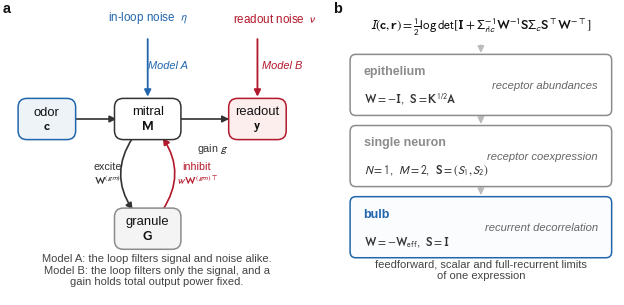

In [5]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

def _box(ax, x, y, w, h, label, fc="white", ec=C_INK, fs=8.5, lw=1.0, tc="#111111"):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h,
                                boxstyle="round,pad=0.012,rounding_size=0.03",
                                linewidth=lw, edgecolor=ec, facecolor=fc, zorder=3))
    ax.text(x, y, label, ha="center", va="center", fontsize=fs, zorder=4, color=tc)

def _arrow(ax, p0, p1, color=C_INK, lw=1.1, style="-|>", rad=0.0, ls="-"):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle=style, mutation_scale=9,
                                 linewidth=lw, color=color, zorder=2, linestyle=ls,
                                 connectionstyle=f"arc3,rad={rad}",
                                 shrinkA=2, shrinkB=2))

fig = plt.figure(figsize=(fig_width(1.0), 3.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.0], wspace=0.12)

# ---------------------------------------------------------------- (a) the circuit
axa = fig.add_subplot(gs[0, 0]); axa.set_axis_off()
axa.set_xlim(0, 1); axa.set_ylim(0, 1)

_box(axa, 0.13, 0.62, 0.17, 0.115, "odor\n$\\mathbf{c}$", fc="#eef3f8", ec=C_MAIN)
_box(axa, 0.47, 0.62, 0.20, 0.115, "mitral\n$\\mathbf{M}$", fc="white", ec=C_INK)
_box(axa, 0.47, 0.25, 0.20, 0.115, "granule\n$\\mathbf{G}$", fc="#f4f4f4", ec=C_CTRL)
_box(axa, 0.84, 0.62, 0.17, 0.115, "readout\n$\\mathbf{y}$", fc="#fdeeee", ec=C_TARGET)

_arrow(axa, (0.215, 0.62), (0.375, 0.62))
_arrow(axa, (0.565, 0.62), (0.755, 0.62))
# reciprocal loop
_arrow(axa, (0.425, 0.565), (0.425, 0.305), color=C_INK, rad=0.35)
_arrow(axa, (0.515, 0.305), (0.515, 0.565), color=C_TARGET, rad=0.35)
axa.text(0.335, 0.435, "excite\n$\\mathbf{W}^{(gm)}$", ha="center", va="center",
         fontsize=7.0, color=C_INK)
axa.text(0.635, 0.435, "inhibit\n$w\\,\\mathbf{W}^{(gm)\\top}$", ha="center", va="center",
         fontsize=7.0, color=C_TARGET)

# noise injections
_arrow(axa, (0.47, 0.90), (0.47, 0.685), color=C_MAIN, lw=1.2)
axa.text(0.47, 0.935, "in-loop noise  $\\boldsymbol{\\eta}$", ha="center", va="bottom",
         fontsize=7.6, color=C_MAIN)
axa.text(0.47, 0.80, "Model A", ha="left", va="center", fontsize=7.2, color=C_MAIN,
         style="italic")

_arrow(axa, (0.84, 0.90), (0.84, 0.685), color=C_TARGET, lw=1.2)
axa.text(0.90, 0.935, "readout noise  $\\boldsymbol{\\nu}$", ha="center", va="bottom",
         fontsize=7.6, color=C_TARGET)
axa.text(0.855, 0.80, "Model B", ha="left", va="center", fontsize=7.2, color=C_TARGET,
         style="italic")

axa.text(0.69, 0.545, "gain $g$", ha="center", va="top", fontsize=7.0, color=C_INK)
axa.text(0.5, 0.055,
         "Model A: the loop filters signal and noise alike.\n"
         "Model B: the loop filters only the signal, and a\n"
         "gain holds total output power fixed.",
         ha="center", va="bottom", fontsize=7.3, color="#444444")
panel(axa, "a", dx=-4, dy=-6)

# ---------------------------------------------------------------- (b) the three limits
axb = fig.add_subplot(gs[0, 1]); axb.set_axis_off()
axb.set_xlim(0, 1); axb.set_ylim(0, 1)

axb.text(0.5, 0.965, "$I(\\mathbf{c},\\mathbf{r})=\\frac{1}{2}\\log\\det"
                     "[\\mathbf{I}+\\Sigma_{r|c}^{-1}\\mathbf{W}^{-1}\\mathbf{S}"
                     "\\Sigma_c\\mathbf{S}^{\\top}\\mathbf{W}^{-\\top}]$",
         ha="center", va="top", fontsize=8.6, color="#111111")

rows = [
    (0.735, "epithelium", "$\\mathbf{W}=-\\mathbf{I}$,  $\\mathbf{S}=\\mathbf{K}^{1/2}\\mathbf{A}$",
     "receptor abundances", C_CTRL),
    (0.495, "single neuron", "$N=1$,  $M=2$,  $\\mathbf{S}=(S_1,S_2)$",
     "receptor coexpression", C_CTRL),
    (0.255, "bulb", "$\\mathbf{W}=-\\mathbf{W}_{\\mathrm{eff}}$,  $\\mathbf{S}=\\mathbf{I}$",
     "recurrent decorrelation", C_MAIN),
]
for y, name, setting, what, col in rows:
    _arrow(axb, (0.5, y + 0.145), (0.5, y + 0.098), color="#bbbbbb", lw=0.9)
    axb.add_patch(FancyBboxPatch((0.045, y - 0.095), 0.91, 0.19,
                                 boxstyle="round,pad=0.008,rounding_size=0.02",
                                 linewidth=1.0, edgecolor=col,
                                 facecolor="#fafcfe" if col == C_MAIN else "white",
                                 zorder=3))
    axb.text(0.085, y + 0.045, name, ha="left", va="center", fontsize=8.2,
             fontweight="bold", color=col, zorder=4)
    axb.text(0.085, y - 0.048, setting, ha="left", va="center", fontsize=7.6,
             color="#333333", zorder=4)
    axb.text(0.915, y, what, ha="right", va="center", fontsize=7.4,
             color="#666666", style="italic", zorder=4)

axb.text(0.5, 0.075, "feedforward, scalar and full-recurrent limits\n"
                     "of one expression",
         ha="center", va="bottom", fontsize=7.3, color="#444444")
panel(axb, "b", dx=-4, dy=-6)

save(fig, "Fig1_framework")
plt.show()

## 4. Recurrent inhibition under two noise models

The central sweep. We vary the inhibitory gain $w$ over four decades and evaluate the
information under both noise conventions, for random and for source-matched wiring. Three
things are being tested.

**The monotonicity result.** Under Model A the information should fall monotonically with
$w$ for every connectivity, with no interior optimum anywhere.

**The interior optimum.** Under Model B it should rise to an interior optimum, but only
when the wiring is matched to the odor sources.

**Robustness of the monotonicity result to the adiabatic reduction.** The reduced
mitral-only description is obtained by eliminating the granule cells at their fixed point.
That step could in principle be what produces the monotone decline. We therefore also
solve the *exact* two-population Lyapunov equation, without any elimination, under three
placements of the in-loop noise: in the mitral population only, in both populations, and in
the granule population only. If the result is an artifact of the reduction, at least one of
these should show an interior optimum.

The sweep is deliberately long: 121 values of $w$ spanning three and a half decades, at 200
independent connectivity seeds each, so that the seed-to-seed spread is resolved rather than
assumed small, and the exact two-population check is run at 5 seeds per condition on a
larger network than the reduced description would need.

In [6]:
# ---------------------------------------------------------------- the w sweep
N_g_main, N_CONNECT_F1 = 200, 10
N_SEEDS = 200
N_W_LOG = 120
w_values = np.concatenate(([0.0], np.logspace(-4, -0.5, N_W_LOG)))

t0 = time.time()
miA   = np.zeros((len(w_values), N_SEEDS))
miB_r = np.zeros((len(w_values), N_SEEDS))
miB_m = np.zeros((len(w_values), N_SEEDS))
flat_r = np.zeros((len(w_values), N_SEEDS))
flat_m = np.zeros((len(w_values), N_SEEDS))

W_rand = [make_wiring(N_m, N_g_main, N_CONNECT_F1, "random", seed=sd)
          for sd in range(N_SEEDS)]
W_match = [make_wiring(N_m, N_g_main, N_CONNECT_F1, "matched", blocks, seed=sd)
           for sd in range(N_SEEDS)]
K_rand = [W.T @ W for W in W_rand]
K_match = [W.T @ W for W in W_match]

for k, w_ in enumerate(w_values):
    for sd in range(N_SEEDS):
        Er = np.eye(N_m) + w_ * K_rand[sd]
        Em = np.eye(N_m) + w_ * K_match[sd]
        miA[k, sd]   = mi_inloop(Sigma_c, Er, sigma_noise)
        miB_r[k, sd] = mi_budget(Sigma_c, Er, sigma_noise, power_budget)
        miB_m[k, sd] = mi_budget(Sigma_c, Em, sigma_noise, power_budget)
        flat_r[k, sd] = spectral_flatness(output_covariance(Sigma_c, Er))
        flat_m[k, sd] = spectral_flatness(output_covariance(Sigma_c, Em))
sweep_secs = time.time() - t0

miA_m, miA_s = miA.mean(1), miA.std(1, ddof=1) / np.sqrt(N_SEEDS)
miBr_m, miBr_s = miB_r.mean(1), miB_r.std(1, ddof=1) / np.sqrt(N_SEEDS)
miBm_m, miBm_s = miB_m.mean(1), miB_m.std(1, ddof=1) / np.sqrt(N_SEEDS)

# per-seed monotonicity of Model A: the strongest form of the check
dA = np.diff(miA, axis=0)
frac_monotone = float((dA <= 1e-12).mean())
worst_increase = float(dA.max())

i_best_m = int(np.argmax(miBm_m))
i_best_r = int(np.argmax(miBr_m))
w_star = float(w_values[i_best_m])
gain_match = 100 * (miBm_m[i_best_m] / I_ff - 1)
gain_rand  = 100 * (miBr_m[i_best_r] / I_ff - 1)
# per-seed optimum, so the optimum itself carries an uncertainty
w_star_seeds = w_values[np.argmax(miB_m, axis=0)]
gain_match_seeds = 100 * (miB_m.max(0) / I_ff - 1)

# where random wiring falls back below the feedforward baseline
below = np.where(miBr_m < I_ff)[0]
w_cross_rand = float(w_values[below[0]]) if len(below) else np.nan

print(f"sweep: {len(w_values)} values of w x {N_SEEDS} seeds x 2 wirings "
      f"({sweep_secs:.0f} s)")
print()
check("Model A at w=0, nats", miA_m[0], 125.87064803723244, fmt="{:.2f}", key="miA_w0")
check("Model A at w=0.1, nats",
      float(np.interp(0.1, w_values, miA_m)), 90.9436084799725, fmt="{:.2f}", key="miA_w01")
check("Model A at w=0.316, nats", miA_m[-1], 68.58464683113593, fmt="{:.2f}", key="miA_wend")
check("Model A steps that decrease (fraction)", frac_monotone, 1.0,
      tol=0.0, fmt="{:.4f}", key="frac_monotone")
check("Model A largest single step, nats", worst_increase, -0.006880182388158573,
      tol=1.0, fmt="{:.2e}", key="worst_increase")
record("modelA_n_steps", dA.size)
record("modelA_n_increasing", int((dA > 0).sum()))
check("Model B matched, w*", w_star, 0.005817091329374358, tol=0.35, fmt="{:.4f}", key="w_star")
check("Model B matched gain, %", gain_match, 10.221139073791164, tol=0.15, fmt="{:.2f}",
      key="gain_match")
check("Model B random gain, %", gain_rand, 1.1991370641501353, tol=0.5, fmt="{:.2f}",
      key="gain_rand")
print(f"  per-seed optimum w* = {np.median(w_star_seeds):.4f} "
      f"[{np.percentile(w_star_seeds,5):.4f}, {np.percentile(w_star_seeds,95):.4f}] "
      f"(5th-95th percentile over {N_SEEDS} seeds)")
print(f"  per-seed matched gain = {gain_match_seeds.mean():.2f} "
      f"+/- {gain_match_seeds.std(ddof=1):.2f} %")
record("gain_match_sd", gain_match_seeds.std(ddof=1))
record("w_star_lo", np.percentile(w_star_seeds, 5))
record("w_star_hi", np.percentile(w_star_seeds, 95))
record("w_cross_rand", w_cross_rand)
for k_, v_ in (("N_SEEDS", N_SEEDS), ("n_w", len(w_values)), ("n_w_log", N_W_LOG),
               ("N_g_main", N_g_main), ("n_connect_f1", N_CONNECT_F1)):
    record(k_, v_)

sweep: 121 values of w x 200 seeds x 2 wirings (28 s)

  [OK  ] Model A at w=0, nats                               computed      125.87   manuscript      125.87
  [OK  ] Model A at w=0.1, nats                             computed       90.94   manuscript       90.94
  [OK  ] Model A at w=0.316, nats                           computed       68.58   manuscript       68.58
  [OK  ] Model A steps that decrease (fraction)             computed      1.0000   manuscript      1.0000
  [OK  ] Model A largest single step, nats                  computed   -6.88e-03   manuscript   -6.88e-03
  [OK  ] Model B matched, w*                                computed      0.0058   manuscript      0.0058
  [OK  ] Model B matched gain, %                            computed       10.22   manuscript       10.22
  [OK  ] Model B random gain, %                             computed        1.20   manuscript        1.20
  per-seed optimum w* = 0.0058 [0.0058, 0.0058] (5th-95th percentile over 200 seeds)
  per-seed m

### Pattern decorrelation at a fixed inhibitory strength

In [7]:
# ---------------------------------------------------------------- decorrelation
W_DECORR = 0.05

def normalized_steady_state(W_eff, S_in, Sigma_c):
    """Gain-normalized steady state; the spontaneous offset drops out of correlations."""
    F = np.linalg.inv(W_eff)
    g2 = np.trace(Sigma_c) / np.trace(F @ Sigma_c @ F.T)
    return np.sqrt(g2) * (F @ S_in)

order = np.argsort(odor_source)
odors_sorted, src_sorted = odors[:, order], odor_source[order]
mask_all = np.zeros((N_ODORS, N_ODORS), dtype=bool)
mask_all[np.triu_indices(N_ODORS, k=1)] = True
mask_same = (src_sorted[:, None] == src_sorted[None, :]) & mask_all
mask_diff = (~(src_sorted[:, None] == src_sorted[None, :])) & mask_all

C_in = np.corrcoef(odors_sorted.T)
ss_in, ds_in = float(C_in[mask_same].mean()), float(C_in[mask_diff].mean())

decorr = {"Random": [], "Matched": []}
for sd in range(N_SEEDS):
    for name, Wl in (("Random", W_rand), ("Matched", W_match)):
        E = np.eye(N_m) + W_DECORR * (Wl[sd].T @ Wl[sd])
        Cc = np.corrcoef(normalized_steady_state(E, odors_sorted, Sigma_c).T)
        decorr[name].append((Cc[mask_same].mean(), Cc[mask_diff].mean()))
decorr = {k: np.array(v) for k, v in decorr.items()}

print(f"decorrelation at w = {W_DECORR}, {N_ODORS} odors, {N_SEEDS} seeds")
print()
check("same-source input correlation", ss_in, 0.9583935735529214, fmt="{:.3f}", key="ss_in")
check("output corr., random wiring", decorr["Random"][:, 0].mean(), 0.9583866629101536,
      fmt="{:.3f}", key="ss_out_random")
check("output corr., matched wiring", decorr["Matched"][:, 0].mean(), 0.30248418092221463,
      tol=0.10, fmt="{:.3f}", key="ss_out_matched")
record("ss_out_matched_sd", decorr["Matched"][:, 0].std(ddof=1))
record("ss_out_random_sd", decorr["Random"][:, 0].std(ddof=1))
record("ds_in", ds_in)
record("ds_out_matched", decorr["Matched"][:, 1].mean())

decorrelation at w = 0.05, 200 odors, 200 seeds

  [OK  ] same-source input correlation                      computed       0.958   manuscript       0.958
  [OK  ] output corr., random wiring                        computed       0.958   manuscript       0.958
  [OK  ] output corr., matched wiring                       computed       0.302   manuscript       0.302


np.float64(0.025739222975032484)

### Fig 2. Two noise models, opposite verdicts

  -> figures/Fig2_two_noise_models.pdf   (7.20 x 2.50 in)


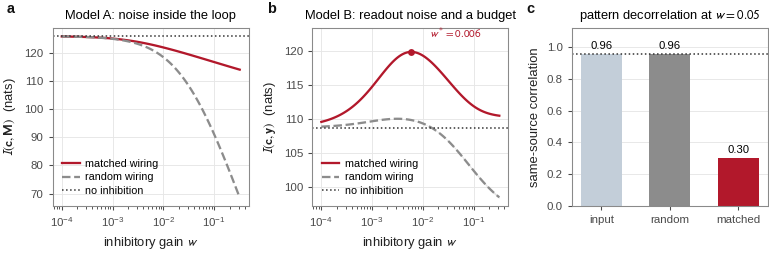

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(fig_width(1.0), 2.5))
ax = axes.ravel()

# (a) Model A, reduced description
miA_match = np.array([[mi_inloop(Sigma_c, np.eye(N_m) + w_ * K_match[sd], sigma_noise)
                       for sd in range(N_SEEDS)] for w_ in w_values]).mean(1)
ax[0].plot(w_values[1:], miA_match[1:], color=C_TARGET, label="matched wiring")
ax[0].plot(w_values[1:], miA_m[1:], color=C_CTRL, ls="--", label="random wiring")
ax[0].fill_between(w_values[1:], (miA_m - 1.96 * miA_s)[1:], (miA_m + 1.96 * miA_s)[1:],
                   color=C_CTRL, alpha=0.22, linewidth=0)
ax[0].axhline(miA_m[0], color=C_INK, ls=":", lw=1.0, label="no inhibition")
ax[0].set_xscale("log"); ax[0].set_xlabel("inhibitory gain $w$")
ax[0].set_ylabel("$I(\\mathbf{c},\\mathbf{M})$  (nats)")
ax[0].set_title("Model A: noise inside the loop", fontsize=8.4)
ax[0].legend(loc="lower left")

# (b) Model B
ax[1].plot(w_values[1:], miBm_m[1:], color=C_TARGET, label="matched wiring")
ax[1].fill_between(w_values[1:], (miBm_m - 1.96 * miBm_s)[1:], (miBm_m + 1.96 * miBm_s)[1:],
                   color=C_TARGET, alpha=0.22, linewidth=0)
ax[1].plot(w_values[1:], miBr_m[1:], color=C_CTRL, ls="--", label="random wiring")
ax[1].fill_between(w_values[1:], (miBr_m - 1.96 * miBr_s)[1:], (miBr_m + 1.96 * miBr_s)[1:],
                   color=C_CTRL, alpha=0.25, linewidth=0)
ax[1].axhline(I_ff, color=C_INK, ls=":", lw=1.0, label="no inhibition")
ax[1].plot([w_star], [miBm_m[i_best_m]], "o", color=C_TARGET, ms=4.5, zorder=5)
_y0, _y1 = ax[1].get_ylim()
ax[1].set_ylim(_y0, _y1 + 0.10 * (_y1 - _y0))
ax[1].annotate(f"$w^*={w_star:.3f}$", xy=(w_star, miBm_m[i_best_m]),
               xytext=(12, 9), textcoords="offset points", fontsize=7.2, color=C_TARGET)
ax[1].set_xscale("log"); ax[1].set_xlabel("inhibitory gain $w$")
ax[1].set_ylabel("$I(\\mathbf{c},\\mathbf{y})$  (nats)")
ax[1].set_title("Model B: readout noise and a budget", fontsize=8.4)
ax[1].legend(loc="lower left")

# (c) decorrelation
labels = ["input", "random", "matched"]
vals = [ss_in, decorr["Random"][:, 0].mean(), decorr["Matched"][:, 0].mean()]
errs = [0.0, decorr["Random"][:, 0].std(ddof=1), decorr["Matched"][:, 0].std(ddof=1)]
cols = [C_FAINT, C_CTRL, C_TARGET]
ax[2].bar(labels, vals, yerr=errs, color=cols, capsize=3, width=0.6,
          error_kw=dict(lw=0.9, ecolor="#555555"))
ax[2].axhline(ss_in, color=C_INK, ls=":", lw=1.0)
for i, v in enumerate(vals):
    ax[2].text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=7.4)
ax[2].set_ylim(0, 1.12)
ax[2].set_ylabel("same-source correlation")
ax[2].set_title(f"pattern decorrelation at $w={W_DECORR}$", fontsize=8.4)
ax[2].grid(axis="x", visible=False)

panels(axes)
fig.tight_layout()
save(fig, "Fig2_two_noise_models")
plt.show()

## 5. The spectral-flatness identity

Under Model B the entire benefit of recurrent inhibition collapses to one number. With
$C_w = \mathbf W_{\mathrm{eff}}^{-1}\Sigma_c\mathbf W_{\mathrm{eff}}^{-\top}$ the output
signal covariance before the compensating gain, and $\mathcal F$ the spectral flatness,

$$I(w)-I(0) = \frac{N_m}{2}\log\frac{\mathcal F(C_w)}{\mathcal F(\Sigma_c)} \qquad
\text{(high signal-to-noise limit).}$$

The identity is derived in the main text as a high-signal-to-noise limit. Here
we ask how good it is at finite signal-to-noise, which is what the rest of the paper
actually uses. We evaluate both sides at every point of the sweep, for both wirings, and we
repeat the comparison across three decades of readout noise, so that the identity's error is
reported as a function of the regime rather than asserted for one.

In [9]:
def flatness_prediction(W_eff, Sigma_c):
    """Right-hand side of the flatness identity, in nats."""
    N = W_eff.shape[0]
    return 0.5 * N * np.log(spectral_flatness(output_covariance(Sigma_c, W_eff))
                            / spectral_flatness(Sigma_c))

# ---- measured against predicted along the main sweep, over many seeds and both wirings
N_SEEDS_FLAT = 20
meas, pred, which = [], [], []
for name, Kl in (("random", K_rand), ("matched", K_match)):
    for sd in range(N_SEEDS_FLAT):
        for w_ in w_values[1:]:
            E = np.eye(N_m) + w_ * Kl[sd]
            meas.append(mi_budget(Sigma_c, E, sigma_noise, power_budget) - I_ff)
            pred.append(flatness_prediction(E, Sigma_c))
            which.append(name)
meas, pred, which = np.array(meas), np.array(pred), np.array(which)
# seed 0 alone, for the curves drawn in Fig 3b
meas0 = {nm: np.array([mi_budget(Sigma_c, np.eye(N_m) + w_ * Kl[0], sigma_noise, power_budget)
                       - I_ff for w_ in w_values[1:]])
         for nm, Kl in (("random", K_rand), ("matched", K_match))}
pred0 = {nm: np.array([flatness_prediction(np.eye(N_m) + w_ * Kl[0], Sigma_c)
                       for w_ in w_values[1:]])
         for nm, Kl in (("random", K_rand), ("matched", K_match))}
record("N_SEEDS_FLAT", N_SEEDS_FLAT)

err = np.abs(meas - pred)
r_mp = float(np.corrcoef(meas, pred)[0, 1])

# The identity is a high-SNR limit. It is excellent wherever the gain-scaled output
# eigenvalues stay well above the readout floor, and degrades once strong inhibition pushes
# the weakest of them down to it. We therefore report the error twice: over the regime the
# paper actually works in (inhibition at or below w = 0.05, which brackets the interior
# optimum), and globally, with the value of w at which the worst case occurs.
w_rep = np.tile(w_values[1:], 2 * N_SEEDS_FLAT)
useful = w_rep <= 0.05
err_useful, r_useful = err[useful], float(np.corrcoef(meas[useful], pred[useful])[0, 1])
w_worst = float(w_rep[int(np.argmax(err))])

# ---- how the identity degrades as the readout noise grows
sig_grid = np.logspace(-2.5, 0.0, 26)
err_by_sigma, gain_by_sigma = [], []
E_star = np.eye(N_m) + w_star * K_match[0]
for s_ in sig_grid:
    m_ = (mi_budget(Sigma_c, E_star, s_, power_budget)
          - mi_budget(Sigma_c, np.eye(N_m), s_, power_budget))
    err_by_sigma.append(abs(m_ - flatness_prediction(E_star, Sigma_c)))
    gain_by_sigma.append(m_)
err_by_sigma = np.array(err_by_sigma); gain_by_sigma = np.array(gain_by_sigma)
i_sig = int(np.argmin(np.abs(sig_grid - sigma_noise)))

# ---- the whitening ceiling: how flat can this architecture get?
F_out_star = spectral_flatness(output_covariance(Sigma_c, E_star))
F_white_gain = 0.5 * N_m * np.log(1.0 / F_in)      # gain if whitening were reachable

print(f"flatness identity checked at {len(meas)} (w, wiring) points")
print()
check("identity, max error for w <= 0.05, nats", err_useful.max(), 0.40953535182510414,
      tol=0.5, fmt="{:.4f}", key="flat_max_err")
check("identity, median error for w <= 0.05, nats", float(np.median(err_useful)),
      0.03180710517716323, tol=0.5, fmt="{:.4f}", key="flat_med_err")
check("identity, correlation for w <= 0.05", r_useful, 0.9998568457729985, tol=0.01,
      fmt="{:.5f}", key="flat_r_useful")
check("identity, global max error, nats", err.max(), 6.0149701304529275, tol=0.5,
      fmt="{:.3f}", key="flat_global_max_err")
print(f"  worst case at w = {w_worst:.3f}, the largest inhibition in the sweep, where the")
print(f"  weakest gain-scaled output modes have fallen to the readout floor.")
record("flat_worst_w", w_worst)
i_star = int(np.argmin(np.abs(w_values[1:] - w_star)))
err_star_seeds = np.abs(meas[which == "matched"].reshape(N_SEEDS_FLAT, -1)[:, i_star]
                        - pred[which == "matched"].reshape(N_SEEDS_FLAT, -1)[:, i_star])
check("identity, error at w* (matched), nats", err_star_seeds.mean(),
      0.16721019213766092, tol=0.5, fmt="{:.4f}", key="flat_err_wstar")
record("flat_err_wstar_sd", err_star_seeds.std(ddof=1))
check("identity, correlation measured vs predicted", r_mp, 0.9801362028512086,
      tol=0.01, fmt="{:.5f}", key="flat_r")
check("output flatness at w*, matched", F_out_star, 0.9987455885287287, fmt="{:.4f}", key="F_out")
check("input flatness", F_in, 0.6354908076050703, fmt="{:.4f}", key="F_in_again")
check("identity error at sigma_out = 0.1, nats", err_by_sigma[i_sig], 0.16767986388521372,
      tol=0.5, fmt="{:.4f}", key="flat_err_sigma01")
realized = meas[which == "matched"].reshape(N_SEEDS_FLAT, -1).max(1).mean()
print(f"  gain if perfect whitening were reachable: {F_white_gain:.2f} nats "
      f"({100*F_white_gain/I_ff:.1f}% of I(0)); actually realized at w*: "
      f"{realized:.2f} nats, {100*realized/F_white_gain:.0f}% of the ceiling")
record("F_white_gain", F_white_gain)
record("realized_gain_nats", realized)
record("flat_err_pct", 100 * err_star_seeds.mean() / realized)
record("realized_frac_of_ceiling", 100 * realized / F_white_gain)
record("F_white_gain_pct", 100 * F_white_gain / I_ff)
record("n_sigma_grid", len(sig_grid))

flatness identity checked at 4800 (w, wiring) points

  [OK  ] identity, max error for w <= 0.05, nats            computed      0.4095   manuscript      0.4095
  [OK  ] identity, median error for w <= 0.05, nats         computed      0.0318   manuscript      0.0318
  [OK  ] identity, correlation for w <= 0.05                computed     0.99986   manuscript     0.99986
  [OK  ] identity, global max error, nats                   computed       6.015   manuscript       6.015
  worst case at w = 0.316, the largest inhibition in the sweep, where the
  weakest gain-scaled output modes have fallen to the readout floor.
  [OK  ] identity, error at w* (matched), nats              computed      0.1672   manuscript      0.1672
  [OK  ] identity, correlation measured vs predicted        computed     0.98014   manuscript     0.98014
  [OK  ] output flatness at w*, matched                     computed      0.9987   manuscript      0.9987
  [OK  ] input flatness                                     c

26

### Fig 3. The benefit of inhibition is a spectral-flatness ratio

  -> figures/Fig3_flatness.pdf   (7.20 x 2.50 in)


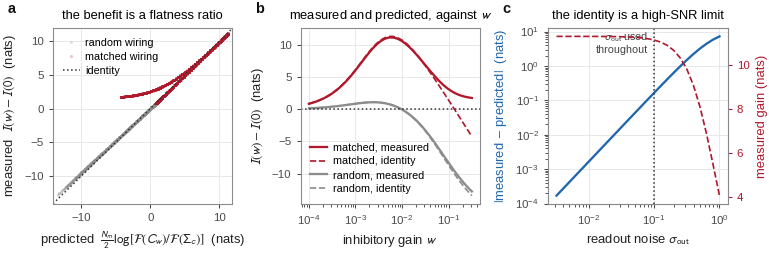

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(fig_width(1.0), 2.5))
ax = axes.ravel()

# (a) measured against predicted
for name, col in (("random", C_CTRL), ("matched", C_TARGET)):
    sel = which == name
    ax[0].plot(pred[sel], meas[sel], "o", color=col, ms=2.0, alpha=0.25,
               label=f"{name} wiring", rasterized=True)
lim = [min(pred.min(), meas.min()) * 1.05, max(pred.max(), meas.max()) * 1.05]
ax[0].plot(lim, lim, color=C_INK, ls=":", lw=1.0, label="identity")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("predicted  $\\frac{N_m}{2}\\log[\\mathcal{F}(C_w)/\\mathcal{F}(\\Sigma_c)]$  (nats)")
ax[0].set_ylabel("measured  $I(w)-I(0)$  (nats)")
ax[0].set_title("the benefit is a flatness ratio", fontsize=8.4)
ax[0].legend(loc="upper left")

# (b) both against w
wv = w_values[1:]
ax[1].plot(wv, meas0["matched"], color=C_TARGET, label="matched, measured")
ax[1].plot(wv, pred0["matched"], color=C_TARGET, ls="--", lw=1.1, label="matched, identity")
ax[1].plot(wv, meas0["random"], color=C_CTRL, label="random, measured")
ax[1].plot(wv, pred0["random"], color=C_CTRL, ls="--", lw=1.1, label="random, identity")
ax[1].axhline(0.0, color=C_INK, ls=":", lw=1.0)
ax[1].set_xscale("log"); ax[1].set_xlabel("inhibitory gain $w$")
ax[1].set_ylabel("$I(w)-I(0)$  (nats)")
ax[1].set_title("measured and predicted, against $w$", fontsize=8.4)
ax[1].legend(loc="lower left", ncol=1)

# (c) identity error against readout noise
ax[2].loglog(sig_grid, np.maximum(err_by_sigma, 1e-6), color=C_MAIN,
             label="identity error")
ax[2].axvline(sigma_noise, color=C_INK, ls=":", lw=1.0)
ax[2].annotate("$\\sigma_{\\mathrm{out}}$ used\nthroughout", xy=(sigma_noise, err_by_sigma[i_sig]),
               xytext=(-4, 26), textcoords="offset points", fontsize=7.0,
               color="#444444", ha="right")
ax2 = ax[2].twinx()
ax2.plot(sig_grid, gain_by_sigma, color=C_TARGET, ls="--", lw=1.1)
ax2.set_ylabel("measured gain (nats)", color=C_TARGET)
ax2.tick_params(axis="y", colors=C_TARGET); ax2.grid(False)
ax[2].set_xlabel("readout noise $\\sigma_{\\mathrm{out}}$")
ax[2].set_ylabel("$|$measured $-$ predicted$|$  (nats)", color=C_MAIN)
ax[2].set_title("the identity is a high-SNR limit", fontsize=8.4)

panels(axes)
fig.tight_layout()
save(fig, "Fig3_flatness")
plt.show()

### Robustness of the interior optimum across stimulus ensembles

In [11]:
# ---------------------------------------------------------------- robustness of the optimum
# How much of this depends on the particular stimulus ensemble? We repeat the Model B sweep
# across within-source correlations, numbers of sources, and granule fan-out, and report
# where the optimum sits and what it is worth.
N_SEEDS_ROBUST = 100

def sweep_optimum(corr, nb, n_connect, n_seeds=N_SEEDS_ROBUST, N=N_m, N_g=200):
    assert n_connect <= N // nb, (
        f"n_connect={n_connect} exceeds the block size {N // nb} (N={N}, nb={nb}); "
        "make_wiring would silently cap it, making this condition indistinguishable "
        "from a smaller fan-out.")
    blk = np.repeat(np.arange(nb), N // nb)
    Sig = generate_odor_covariance(N, nb, corr)
    P = np.trace(Sig)
    I0 = mi_budget(Sig, np.eye(N), sigma_noise, P)
    ws = np.logspace(-4, -1, 40)
    best_w, best_g = [], []
    for sd in range(n_seeds):
        Wm = make_wiring(N, N_g, n_connect, "matched", blk, seed=sd)
        Km = Wm.T @ Wm
        vals = np.array([mi_budget(Sig, np.eye(N) + w_ * Km, sigma_noise, P) for w_ in ws])
        best_w.append(ws[int(np.argmax(vals))]); best_g.append(100 * (vals.max() / I0 - 1))
    return (np.median(best_w), np.mean(best_g), np.std(best_g, ddof=1),
            spectral_flatness(Sig))

t0 = time.time()
rows = []
for corr in (0.2, 0.4, 0.6, 0.8):
    wS, gS, gsd, Fs = sweep_optimum(corr, n_blocks, 10)
    rows.append([f"correlation {corr}", f"{Fs:.3f}", f"{wS:.4f}", f"{gS:.2f} +/- {gsd:.2f}"])
    record(f"robust_corr{int(100*corr)}_gain", gS)
    record(f"robust_corr{int(100*corr)}_w", wS); record(f"robust_corr{int(100*corr)}_F", Fs)

# Fan-out is capped at the block size (N // nb), so the widest source count tested (10
# sources of 5 glomeruli each) forces fan-out <= 5. We use that fan-out for all three rows,
# rather than letting the wider-block conditions silently cap down to it, so the three rows
# differ only in the number of sources.
NC_SOURCES = N_m // 10
for nb_ in (2, 5, 10):
    wS, gS, gsd, Fs = sweep_optimum(0.6, nb_, NC_SOURCES)
    rows.append([f"{nb_} sources", f"{Fs:.3f}", f"{wS:.4f}", f"{gS:.2f} +/- {gsd:.2f}"])
    record(f"robust_nb{nb_}_gain", gS)
    record(f"robust_nb{nb_}_w", wS); record(f"robust_nb{nb_}_F", Fs)
record("robust_nc_sources", NC_SOURCES)
# Fan-out sweep, at the number of sources used throughout the main text (five, block size
# 10): both alternative values stay within that block size, so none of them is silently
# capped back down to the baseline.
for nc in (6, 8, 10):
    wS, gS, gsd, Fs = sweep_optimum(0.6, n_blocks, nc)
    rows.append([f"fan-out {nc}", f"{Fs:.3f}", f"{wS:.4f}", f"{gS:.2f} +/- {gsd:.2f}"])
    record(f"robust_nc{nc}_gain", gS)
    record(f"robust_nc{nc}_w", wS); record(f"robust_nc{nc}_F", Fs)
robust_secs = time.time() - t0

show_table(rows, ["ensemble", "F(Sigma_c)", "w*", "gain over feedforward (%)"],
           title=f"where the interior optimum sits, across ensembles "
                 f"({N_SEEDS_ROBUST} seeds each, {robust_secs:.0f} s)")
print()
print("The optimum exists in every condition. It is worth more when the input spectrum is")
print("less flat, which is what the flatness identity predicts.")
gains = [v for k, v in RESULTS.items() if k.startswith("robust_") and k.endswith("_gain")]
record("robust_min_gain", min(gains)); record("robust_max_gain", max(gains))
record("robust_n_conditions", len(gains))
record("robust_n_seeds", N_SEEDS_ROBUST)

where the interior optimum sits, across ensembles (100 seeds each, 12 s)
ensemble         F(Sigma_c)  w*      gain over feedforward (%)
--------------------------------------------------------------
correlation 0.2  0.930       0.0017  1.49 +/- 0.01
correlation 0.4  0.797       0.0035  4.84 +/- 0.02
correlation 0.6  0.635       0.0059  10.22 +/- 0.03
correlation 0.8  0.452       0.0084  19.34 +/- 0.04
2 sources        0.570       0.0289  10.13 +/- 0.19
5 sources        0.635       0.0242  9.10 +/- 0.14
10 sources       0.715       0.0143  7.22 +/- 0.09
fan-out 6        0.635       0.0170  9.59 +/- 0.10
fan-out 8        0.635       0.0100  10.05 +/- 0.05
fan-out 10       0.635       0.0059  10.22 +/- 0.03

The optimum exists in every condition. It is worth more when the input spectrum is
less flat, which is what the flatness identity predicts.


100

## 6. Matched wiring is discoverable by a local rule

Everywhere above, source-matched wiring is imposed by hand. That is a fair way to ask what
the architecture buys, but it leaves open whether anything could build it. The
budget-constrained objective has a closed-form gradient in the granule-to-mitral weights
(Supporting Information), so each step of an optimizer costs one $O(N_m^3)$ pass rather
than one information evaluation per nonzero weight, and we can simply run projected gradient
ascent from random sparse wiring and look at what it finds.

The sparsity pattern is held fixed and the weights are clipped to $[0,1]$ rather than
renormalized, since rescaling the whole matrix would silently change the effective
inhibition. The optimizer never sees the block labels.

The ascent runs on the full fifty-cell network with the full granule population, for 8000
iterations from each of 40 random restarts, with a step size set by backtracking so that the
objective never decreases and no learning rate has to be tuned.

In [12]:
def mi_and_grad(W_gm, Sigma_c, w, sigma, budget):
    """Model B information and its analytic gradient with respect to W_gm."""
    N = W_gm.shape[1]
    E = np.eye(N) + w * (W_gm.T @ W_gm)
    A = np.linalg.inv(E)
    C = A @ Sigma_c @ A.T
    T = np.trace(C)
    kappa = budget / sigma**2
    B = kappa * C / T
    IB = np.linalg.inv(np.eye(N) + B)
    mi = 0.5 * np.linalg.slogdet(np.eye(N) + B)[1]
    G = IB - (np.trace(IB @ C) / T) * np.eye(N)
    Q = Sigma_c @ A @ G + G @ A @ Sigma_c
    dW = -(kappa * w / T) * (W_gm @ A @ Q @ A)
    return mi, dW

def ascend(N_m_, N_g_, n_connect, Sigma_c_, blk, sigma=sigma_noise, n_iter=4000,
           lr0=200.0, w_fixed=0.02, seed=0, log_every=10):
    """Projected gradient ascent with a step size that backtracks on any decrease."""
    W = make_wiring(N_m_, N_g_, n_connect, "random", seed=seed)
    mask = W > 0
    budget = np.trace(Sigma_c_)
    lr = lr0
    mi, dW = mi_and_grad(W, Sigma_c_, w_fixed, sigma, budget)
    hist_mi, hist_pur, hist_it = [mi], [block_purity(W, blk)], [0]
    for it in range(1, n_iter + 1):
        for _ in range(40):                        # backtracking line search
            W_try = np.clip(W + lr * dW * mask, 0.0, 1.0)
            mi_try, dW_try = mi_and_grad(W_try, Sigma_c_, w_fixed, sigma, budget)
            if mi_try >= mi:
                break
            lr *= 0.5
        else:
            break                                  # step size collapsed: converged
        W, mi, dW = W_try, mi_try, dW_try
        lr *= 1.05
        if it % log_every == 0 or it == n_iter:
            hist_mi.append(mi); hist_pur.append(block_purity(W, blk)); hist_it.append(it)
    return W, np.array(hist_it), np.array(hist_mi), np.array(hist_pur)

W_GRAD, N_RESTARTS, N_ITER = 0.02, 100, 8000
t0 = time.time()
runs = [ascend(N_m, N_g_main, N_CONNECT_F1, Sigma_c, blocks, n_iter=N_ITER, seed=s)
        for s in range(N_RESTARTS)]
grad_secs = time.time() - t0
best = int(np.argmax([r[2][-1] for r in runs]))
W_opt, it_hist, mi_hist, pur_hist = runs[best]

def ref_mi(kind, n_refs=N_SEEDS):
    return np.array([mi_budget(Sigma_c, np.eye(N_m) + W_GRAD * (W.T @ W),
                               sigma_noise, power_budget)
                     for W in ((W_rand if kind == "random" else W_match)[:n_refs])])

mi_rand_ref = ref_mi("random"); mi_match_ref = ref_mi("matched")
chance_purity = float(np.mean([block_purity(W) for W in W_rand]))
gap_closed = 100 * (mi_hist[-1] - mi_hist[0]) / (mi_match_ref.mean() - mi_hist[0])
final_all = np.array([r[2][-1] for r in runs])
F_opt = spectral_flatness(output_covariance(Sigma_c, np.eye(N_m) + W_GRAD * (W_opt.T @ W_opt)))

print(f"gradient ascent: {N_RESTARTS} restarts x {N_ITER} iterations at w = {W_GRAD}, "
      f"N_m = {N_m}, N_g = {N_g_main}  ({grad_secs:.0f} s)")
print()
show_table(
    [["feedforward (w=0)", f"{I_ff:.3f}", "-"],
     ["random wiring", f"{mi_rand_ref.mean():.3f}", f"{chance_purity:.3f}"],
     ["ascent, start", f"{mi_hist[0]:.3f}", f"{pur_hist[0]:.3f}"],
     [f"ascent, end (best of {N_RESTARTS})", f"{mi_hist[-1]:.3f}", f"{pur_hist[-1]:.3f}"],
     ["hand-designed matched", f"{mi_match_ref.mean():.3f}", "1.000"]],
    ["network", "MI (nats)", "block purity"],
    title=f"projected gradient ascent at w = {W_GRAD}")
print()
check("ascent, MI gain, nats", mi_hist[-1] - mi_hist[0], 7.957549102952754,
      tol=0.1, fmt="{:.3f}", key="grad_gain")
check("ascent, gap to matched closed, %", gap_closed, 99.25389120895525, tol=0.15,
      fmt="{:.1f}", key="grad_gap_closed")
check("ascent, block purity, start", pur_hist[0], 0.36599999999999994, tol=0.05,
      fmt="{:.3f}", key="grad_purity_start")
check("ascent, block purity, end", pur_hist[-1], 0.854817361618958, tol=0.05,
      fmt="{:.3f}", key="grad_purity_end")
check("chance block purity", chance_purity, 0.3540149999999999, tol=0.03,
      fmt="{:.3f}", key="chance_purity")
check("ascent, spread over restarts (nats)", final_all.std(ddof=1), 0.1303977113038188,
      tol=1.0, fmt="{:.4f}", key="grad_restart_sd")
check("ascent, output flatness", F_opt, 0.8974039838721013, tol=0.05, fmt="{:.4f}", key="grad_F")
record("F_match_at_wgrad",
       np.mean([spectral_flatness(output_covariance(
           Sigma_c, np.eye(N_m) + W_GRAD * (W.T @ W))) for W in W_match[:N_SEEDS]]))
record("mi_rand_ref", mi_rand_ref.mean())
record("mi_match_ref", mi_match_ref.mean())
record("grad_mi_end", mi_hist[-1])
record("grad_mi_start", mi_hist[0])
record("N_RESTARTS", N_RESTARTS); record("N_ITER", N_ITER); record("w_grad", W_GRAD)
record("grad_excess_over_matched", mi_hist[-1] - mi_match_ref.mean())

gradient ascent: 100 restarts x 8000 iterations at w = 0.02, N_m = 50, N_g = 200  (829 s)

projected gradient ascent at w = 0.02
network                    MI (nats)  block purity
--------------------------------------------------
feedforward (w=0)          108.729    -
random wiring              108.047    0.354
ascent, start              109.270    0.366
ascent, end (best of 100)  117.227    0.855
hand-designed matched      117.287    1.000

  [OK  ] ascent, MI gain, nats                              computed       7.958   manuscript       7.958
  [OK  ] ascent, gap to matched closed, %                   computed        99.3   manuscript        99.3
  [OK  ] ascent, block purity, start                        computed       0.366   manuscript       0.366
  [OK  ] ascent, block purity, end                          computed       0.855   manuscript       0.855
  [OK  ] chance block purity                                computed       0.354   manuscript       0.354
  [OK  ] ascent, sprea

np.float64(-0.05981828287602298)

### Fig 4. Gradient ascent finds the source-matched architecture

  -> figures/Fig4_gradient_ascent.pdf   (7.50 x 2.30 in)


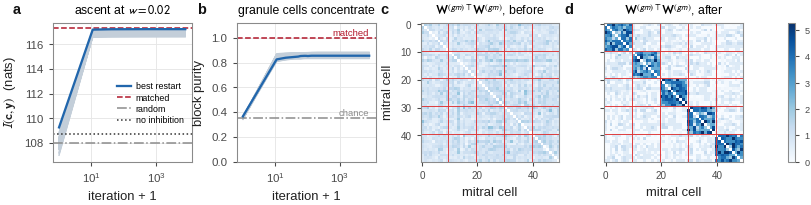

In [13]:
# The shared-target matrix before and after the best run, on one common color scale.
W_init = make_wiring(N_m, N_g_main, N_CONNECT_F1, "random", seed=best)
def _normed_K(Wm):
    K = Wm.T @ Wm
    off = ~np.eye(K.shape[0], dtype=bool)
    K = K / K[off].mean()          # relative to its own mean off-diagonal entry
    K[~off] = np.nan
    return K
K_before, K_after = _normed_K(W_init), _normed_K(W_opt)
vmax = float(np.nanpercentile(np.concatenate([K_before.ravel(), K_after.ravel()]), 99.5))

# Plot data is dumped so the layout can be retuned without rerunning the notebook.
np.savez_compressed(os.path.join(OUTDIR, "figdata_fig3.npz"),
                    it_hist=it_hist, mi_hist=mi_hist, pur_hist=pur_hist,
                    runs_it=np.array([r[1] for r in runs], dtype=object),
                    runs_mi=np.array([r[2] for r in runs], dtype=object),
                    runs_pur=np.array([r[3] for r in runs], dtype=object),
                    mi_match=mi_match_ref.mean(), mi_rand=mi_rand_ref.mean(), I_ff=I_ff,
                    chance=chance_purity, K_before=K_before, K_after=K_after, vmax=vmax,
                    n_blocks=n_blocks, N_m=N_m, N_ITER=N_ITER, W_GRAD=W_GRAD)

def draw_fig3(W=WIDE_W, H=WIDE_H, name="Fig4_gradient_ascent"):
    """One row of four panels, sized for the full text width plus the left margin."""
    fig = plt.figure(figsize=(W, H))
    gs = fig.add_gridspec(1, 5, wspace=0.40, width_ratios=[1, 1, 1, 1, 0.05])
    axA, axB, axC, axD = (fig.add_subplot(gs[0, i]) for i in range(4))
    cax = fig.add_subplot(gs[0, 4])
    for axx in (axA, axB):
        axx.set_box_aspect(1.0)      # same square box as the two matrix panels

    # (a) MI against iteration
    for r in runs:
        axA.plot(r[1] + 1, r[2], color=C_FAINT, lw=0.7, zorder=1)
    axA.plot(it_hist + 1, mi_hist, color=C_MAIN, lw=1.5, zorder=3, label="best restart")
    axA.set_xscale("log")
    axA.axhline(mi_match_ref.mean(), color=C_TARGET, ls="--", lw=1.0, label="matched")
    axA.axhline(mi_rand_ref.mean(), color=C_CTRL, ls="-.", lw=1.0, label="random")
    axA.axhline(I_ff, color=C_INK, ls=":", lw=1.0, label="no inhibition")
    axA.set_xlabel("iteration + 1"); axA.set_ylabel("$I(\\mathbf{c},\\mathbf{y})$  (nats)")
    axA.set_title(f"ascent at $w={W_GRAD}$", fontsize=8.0)
    axA.legend(loc="center right", bbox_to_anchor=(1.0, 0.42), fontsize=5.8,
               labelspacing=0.25)

    # (b) purity against iteration
    for r in runs:
        axB.plot(r[1] + 1, r[3], color=C_FAINT, lw=0.7, zorder=1)
    axB.plot(it_hist + 1, pur_hist, color=C_MAIN, lw=1.5, zorder=3)
    axB.set_xscale("log")
    axB.axhline(1.0, color=C_TARGET, ls="--", lw=1.0)
    axB.axhline(chance_purity, color=C_CTRL, ls="-.", lw=1.0)
    axB.text(N_ITER, 1.0, "matched", ha="right", va="bottom", fontsize=6.2, color=C_TARGET)
    axB.text(N_ITER, chance_purity, "chance", ha="right", va="bottom",
             fontsize=6.2, color=C_CTRL)
    axB.set_ylim(0, 1.12)
    axB.set_xlabel("iteration + 1"); axB.set_ylabel("block purity")
    axB.set_title("granule cells concentrate", fontsize=8.0)

    # (c, d) the shared-target matrix before and after, one shared colorbar
    for axx, K, ttl in ((axC, K_before, "before"), (axD, K_after, "after")):
        im = axx.imshow(K, cmap=seq_cmap(0.0, 1.0), interpolation="nearest",
                        vmin=0.0, vmax=vmax)
        for b in range(1, n_blocks):
            axx.axhline(b * N_m / n_blocks - 0.5, color="#d33", lw=0.6)
            axx.axvline(b * N_m / n_blocks - 0.5, color="#d33", lw=0.6)
        axx.set_title(f"$\\mathbf{{W}}^{{(gm)\\top}}\\mathbf{{W}}^{{(gm)}}$, {ttl}",
                      fontsize=8.0)
        axx.set_xlabel("mitral cell"); axx.grid(False)
        axx.tick_params(labelsize=6.5)
    axC.set_ylabel("mitral cell")
    axD.set_yticklabels([])
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=6.0)

    for axx, lab in ((axA, "a"), (axB, "b"), (axC, "c"), (axD, "d")):
        panel(axx, lab, dx=-26, dy=4)
    fig.subplots_adjust(left=0.055, right=0.955, bottom=0.20, top=0.86)
    # the square panels are shorter than their gridspec slot, so match the colorbar to them
    fig.canvas.draw()
    pd, pc = axD.get_position(), cax.get_position()
    cax.set_position([pc.x0, pd.y0, pc.width, pd.height])
    save(fig, name)
    return fig

fig = draw_fig3()
plt.show()

## 9. Chow et al.'s network: neurogenesis builds matched wiring

Everything above uses a stimulus ensemble and a matched wiring that we constructed. Here
the same analysis is repeated on the network of Chow, Wick & Riecke (2012) itself.

**What is theirs.** The eight glomerular activation patterns ($N_m = 424$ glomeruli) that
drive all of their simulations, recovered from the published figures in our reproduction of
that paper and shipped here as `data/chow2012_stimuli.npz`; their network parameters
($n_{\rm connect}=8$, $w=0.005$, $M_{sp}=1$, $G_{\min}=1.2$, $R_0=0.1$, $\gamma=20$); and
their neurogenesis rule, in which granule cells are added with random connections and
survive only if they are active enough across the odor set (`chow_model.py`, the engine of
that reproduction, unchanged). At fixed connectivity their steady state is exactly our
$\mathbf W_{\rm eff} = \mathbf I + w\,\mathbf W^{(gm)\top}\mathbf W^{(gm)}$, which the cell
below checks against their engine.

**What we add.** Their model has no noise, so we add ours (Model A and Model B, $\sigma=0.1$).
Our formula needs a stimulus ensemble with a covariance, so we take Gaussian mixtures that
vary around the average odor with the covariance of the eight patterns. It is seven
dimensional, and every information below is computed in that seven-dimensional stimulus
space with the $M\times M$ form of the formula. It is scaled, like the synthetic ensemble,
so that the average glomerulus has unit input variance.

**What we compare.** The grown network (three seeds) against random wiring with the same
number of granule cells and connections per cell, and against wiring found by gradient
ascent on the Model B information, started from that random wiring.

In [14]:
import sys
sys.path.insert(0, os.path.abspath("."))
import chow_model as chow

_d = np.load(os.path.join("data", "chow2012_stimuli.npz"), allow_pickle=True)
CH_S = _d["S"]                                   # (8 odors, 424 glomeruli)
CH_NAMES = _d["names"]                            # odor labels, in the order of the rows of S
CH_C_pub = _d["C_published_out"]                  # output correlations decoded from their Fig 2Cii
CH_C_pub_in = _d["C_published_in"]                # input correlations decoded from their Fig 2Ci
CH_Nm = CH_S.shape[1]
CH_P = dict(Nm=CH_Nm, nconnect=8, b=33, w=0.005, Msp=1.0, Gmin=1.2, R0=0.1, gamma=20.0)
CH_KAPPA, CH_T = 4.0, 2500      # 4x their influx reaches the same steady state in 2500 steps
CH_PAIRS = [(0, 1), (2, 3)]     # the enantiomer pairs (+/-limonene, +/-carvone)
CH_W = CH_P["w"]
CH_SEEDS = list(range(10))
CH_IU = np.triu_indices(CH_Nm, 1)

def ch_factor(X):
    """A with Sigma_c = A^T A, restricted to the directions in which the ensemble varies,
    scaled so that the average glomerulus has unit input variance."""
    ev, U = np.linalg.eigh(X.T @ X)
    keep = ev > 1e-9 * ev.max()
    A = (U[:, keep] * np.sqrt(ev[keep])).T
    return A * np.sqrt(CH_Nm / np.trace(A.T @ A))

CH_A = ch_factor(CH_S - CH_S.mean(0, keepdims=True))      # odor-identity ensemble
CH_A_INT = ch_factor(CH_S)                                  # identity plus total concentration
CH_BUDGET = float(CH_Nm)
CH_d = CH_A.shape[0]

def ch_K(exc, V=None):
    """Shared-target matrix W^T W from each granule cell's partners (and weights)."""
    V = np.ones(exc.shape) if V is None else V
    idx = exc[:, :, None].astype(np.int64) * CH_Nm + exc[:, None, :].astype(np.int64)
    return np.bincount(idx.ravel(), weights=(V[:, :, None] * V[:, None, :]).ravel(),
                       minlength=CH_Nm * CH_Nm).reshape(CH_Nm, CH_Nm)

def ch_filter(K, w):
    return np.linalg.inv(np.eye(CH_Nm) + w * K)

def ch_O(A, X):
    Y = A @ X
    return Y @ Y.T                                  # overlaps of the filtered odor patterns

def ch_miA(A, X, sig=sigma_noise):
    return 0.5 * np.linalg.slogdet(np.eye(A.shape[0]) + (2 / sig**2) * A @ X @ A.T)[1]

def ch_miB(A, X, sig=sigma_noise, P=CH_BUDGET):
    O = ch_O(A, X)
    return 0.5 * np.linalg.slogdet(np.eye(A.shape[0]) + P / (sig**2 * np.trace(O)) * O)[1]

def ch_ceiling(A, sig=sigma_noise, P=CH_BUDGET):
    k = A.shape[0]
    return 0.5 * k * np.log(1 + P / (k * sig**2))  # equal power in every stimulus direction

def ch_grad(A, exc, V, w, sig=sigma_noise, P=CH_BUDGET):
    """Model B information and its gradient with respect to the graded granule weights."""
    X = ch_filter(ch_K(exc, V), w); O = ch_O(A, X); k = A.shape[0]
    t = np.trace(O); c = P / (sig**2 * t)
    I = 0.5 * np.linalg.slogdet(np.eye(k) + c * O)[1]
    Q = np.linalg.inv(np.eye(k) + c * O); alpha = np.trace(Q @ O) / t
    H = A.T @ (0.5 * c * (Q - alpha * np.eye(k))) @ A
    Gam = -w * X @ (X @ H + H @ X) @ X; Gam = 0.5 * (Gam + Gam.T)
    return I, 2 * np.einsum("jm,jmn->jn", V, Gam[exc[:, :, None], exc[:, None, :]])

def ch_grow(Gmin, seed):
    p = dict(CH_P, Gmin=Gmin, b=CH_P["b"] * CH_KAPPA)
    net = chow.ChowNetwork(CH_S, rng=np.random.default_rng(seed), **p)
    hist = []
    for k in range(CH_T):
        net.step()
        if k % 100 == 0:
            hist.append(net.Ng)
    return net, np.array(hist)

def ch_random(Ng, seed):
    return np.random.default_rng(10_000 + seed).random((Ng, CH_Nm)).argpartition(7, axis=1)[:, :8]

def ch_chow_measures(K, w=CH_W):
    """Chow et al.'s own decorrelation measures on the deterministic steady state."""
    M = np.linalg.solve(np.eye(CH_Nm) + w * K, (CH_P["Msp"] + CH_S).T)
    C = chow.pearson_corr_matrix(M)
    return chow.mean_corr(C), chow.top_corr(C, CH_PAIRS), M.mean()

def ch_align(K):
    Sig = CH_A.T @ CH_A
    return float(np.corrcoef(K[CH_IU], Sig[CH_IU])[0, 1])

def ch_flat(O):
    return spectral_flatness(O)

# ---------------------------------------------------------------- grow the networks
t0 = time.time()
CH_NETS = {}
for s in CH_SEEDS:
    net, hist = ch_grow(1.2, s)
    Ka = ch_K(net.exc)
    assert np.allclose(CH_W * Ka, net.rebuild_W()), "our W_eff must be their steady state"
    CH_NETS[s] = dict(Ng=net.Ng, Ka=Ka, Kr=ch_K(ch_random(net.Ng, s)),
                      drift=100 * (hist[-1] - hist[-6]) / hist[-1])
    print(f"seed {s}: {net.Ng} granule cells, change over the last 500 steps "
          f"{CH_NETS[s]['drift']:+.2f}%   ({time.time() - t0:.0f} s)")
ch_Ng = np.mean([CH_NETS[s]["Ng"] for s in CH_SEEDS])

# ---------------------------------------------------------------- their decorrelation measure
Cin = chow.pearson_corr_matrix(CH_S.T)
# The recovered patterns are validated against the one published statistic of the input
# ensemble: the correlation matrix of their Fig 2Ci, decoded from the same figure.
_iu8 = np.triu_indices(len(CH_S), 1)
ch_recov_err = float(np.abs(Cin - CH_C_pub_in)[_iu8].max())
# One color step of that figure's scale, read off the decoded values themselves: the
# smallest nonzero gap between distinct decoded correlations.
_dec = np.unique(np.round(CH_C_pub_in[_iu8], 6))
ch_cstep = float(np.diff(_dec).min())
print(f"recovered input correlations agree with their published Fig 2Ci to "
      f"{ch_recov_err:.3f} (largest absolute difference over the {_iu8[0].size} odor pairs), "
      f"within one color step of that figure's scale ({ch_cstep:.3f})")
# Their Fig 2A places one image twice, so the panel labels cannot all be right. The
# assignment of panels to odorants was therefore recovered from this correlation matrix,
# which records the ensemble independently of the layout: every assignment is scored, and
# the second best is reported here to show that the winner is not a close call.
import itertools as _it
_perm_err = sorted(float(np.abs(Cin[np.ix_(p, p)] - CH_C_pub_in)[_iu8].max())
                   for p in _it.permutations(range(len(CH_S))))
ch_recov_next = _perm_err[1]
print(f"  of the {len(_perm_err)} assignments of panels to odorants, the best is the one "
      f"used here; the next best disagrees by {ch_recov_next:.3f}")
record("ch_recov_err", ch_recov_err)
record("ch_recov_next", ch_recov_next)
record("ch_cstep", ch_cstep)
record("ch_n_levels", int(np.unique(CH_S).size))
record("ch_S_lo", float(CH_S.min())); record("ch_S_hi", float(CH_S.max()))
ad = np.array([ch_chow_measures(CH_NETS[s]["Ka"]) for s in CH_SEEDS])
rd = np.array([ch_chow_measures(CH_NETS[s]["Kr"]) for s in CH_SEEDS])
ch_top = dict(input=chow.top_corr(Cin, CH_PAIRS), published=chow.top_corr(CH_C_pub, CH_PAIRS),
              grown=ad[:, 1].mean(), random=rd[:, 1].mean())
print()
show_table([[k, f"{v:.3f}"] for k, v in ch_top.items()], ["", "enantiomer correlation"],
           title="Chow et al.'s decorrelation measure at w = 0.005")
print(f"mean mitral activity of the grown network: {ad[:, 2].mean():.3f} "
      f"(their steady-state value G_min/n_connect = {1.2 / 8:.3f})")

# ---------------------------------------------------------------- is the grown wiring matched?
al_a = np.array([ch_align(CH_NETS[s]["Ka"]) for s in CH_SEEDS])
al_r = np.array([ch_align(CH_NETS[s]["Kr"]) for s in CH_SEEDS])

# ---------------------------------------------------------------- the inhibitory-strength sweep
CH_WS = np.concatenate([[0.0], np.logspace(-5, -1, 25)])
ch_sw = {k: np.zeros((len(CH_SEEDS), len(CH_WS))) for k in ("IA_a", "IA_r", "IB_a", "IB_r", "F_a", "F_r")}
for i, s in enumerate(CH_SEEDS):
    for j, w_ in enumerate(CH_WS):
        for tag, K in (("a", CH_NETS[s]["Ka"]), ("r", CH_NETS[s]["Kr"])):
            X = ch_filter(K, w_)
            ch_sw["IA_" + tag][i, j] = ch_miA(CH_A, X)
            ch_sw["IB_" + tag][i, j] = ch_miB(CH_A, X)
            ch_sw["F_" + tag][i, j] = ch_flat(ch_O(CH_A, X))
ch_Iff = ch_sw["IB_a"][0, 0]
ch_Imax = ch_ceiling(CH_A)
ch_avail = ch_Imax - ch_Iff
ch_F_in = ch_flat(CH_A @ CH_A.T)
jC = int(np.argmin(np.abs(CH_WS - CH_W)))
ch_maxstep = max(np.diff(ch_sw["IA_a"], axis=1).max(), np.diff(ch_sw["IA_r"], axis=1).max())
ch_gain_a = ch_sw["IB_a"][:, jC] - ch_Iff
ch_gain_r = ch_sw["IB_r"][:, jC] - ch_Iff
ch_gain_sat = ch_sw["IB_a"][:, -1] - ch_Iff
ch_interior = np.mean([int(np.argmax(ch_sw["IB_a"][i])) < len(CH_WS) - 1 for i in range(len(CH_SEEDS))])

# flatness identity in stimulus space
_pred = 0.5 * CH_d * np.log(np.r_[ch_sw["F_a"].ravel(), ch_sw["F_r"].ravel()] / ch_F_in)
_meas = np.r_[ch_sw["IB_a"].ravel(), ch_sw["IB_r"].ravel()] - ch_Iff
ch_flat_err = float(np.abs(_pred - _meas).max())

# ---------------------------------------------------------------- gradient ascent from random wiring
CH_N_ITER = 1000
def ch_ascend(A, exc, w, n_iter=CH_N_ITER):
    V = np.ones(exc.shape); I, g = ch_grad(A, exc, V, w)
    eta = 0.05 / np.abs(g).max(); traj = [I]
    for _ in range(n_iter):
        Vn = np.clip(V + eta * g, 0.0, 1.0)
        In = ch_miB(A, ch_filter(ch_K(exc, Vn), w))
        if In > I:
            V = Vn; I, g = ch_grad(A, exc, V, w); eta *= 1.05
        else:
            eta *= 0.5
        traj.append(I)
    return V, np.array(traj)

CH_GA = {}
for s in CH_SEEDS:
    exc_r = ch_random(CH_NETS[s]["Ng"], s)
    V, traj = ch_ascend(CH_A, exc_r, CH_W)
    Kg = ch_K(exc_r, V)
    CH_GA[s] = dict(traj=traj, F=ch_flat(ch_O(CH_A, ch_filter(Kg, CH_W))), align=ch_align(Kg),
                    top=ch_chow_measures(Kg)[1])
ch_gain_g = np.array([CH_GA[s]["traj"][-1] for s in CH_SEEDS]) - ch_Iff
print(f"\ngradient ascent done ({time.time() - t0:.0f} s)")

# ---------------------------------------------------------------- how selective must neurogenesis be?
CH_GMINS = [0.3, 0.6, 0.9, 1.2, 1.5, 1.8]
CH_GMIN_SEEDS = CH_SEEDS[:3]      # each threshold is grown at this many seeds and averaged
ch_gsw = []
for gm in CH_GMINS:
    per_seed = []
    for sd_ in CH_GMIN_SEEDS:
        if gm == CH_P["Gmin"]:
            K = CH_NETS[sd_]["Ka"]; Ng_ = CH_NETS[sd_]["Ng"]; drift = CH_NETS[sd_]["drift"]
        else:
            net, hist = ch_grow(gm, sd_)
            K, Ng_, drift = ch_K(net.exc), net.Ng, 100 * (hist[-1] - hist[-6]) / hist[-1]
        per_seed.append([Ng_, drift, ch_align(K),
                         ch_miB(CH_A, ch_filter(K, CH_W)) - ch_Iff])
    a_ = np.array(per_seed, dtype=float)
    ch_gsw.append(dict(Gmin=gm, Ng=a_[:, 0].mean(),
                       drift=a_[int(np.argmax(np.abs(a_[:, 1]))), 1],
                       align=a_[:, 2].mean(), gain=a_[:, 3].mean(),
                       gain_sd=a_[:, 3].std(ddof=1)))
ch_gfrac = np.array([100 * g["gain"] / ch_avail for g in ch_gsw])
print(f"G_min sweep done ({time.time() - t0:.0f} s)")
show_table([[f"{g['Gmin']:.1f}", f"{g['Ng']:.0f}", f"{g['drift']:+.2f}%",
             f"{g['align']:.3f}", f"{g['gain']:+.3f} +/- {g['gain_sd']:.3f}", f"{f_:.0f}%"]
            for g, f_ in zip(ch_gsw, ch_gfrac)],
           ["G_min", "granule cells", "worst drift", "alignment", "Model B gain",
            "of available"],
           title=f"survival threshold sweep, each network at w = 0.005, "
                 f"{len(CH_GMIN_SEEDS)} seeds per threshold")

# ---------------------------------------------------------------- when total concentration fluctuates too
ch_int_Iff = ch_miB(CH_A_INT, np.eye(CH_Nm))
ch_int_a = ch_miB(CH_A_INT, ch_filter(CH_NETS[0]["Ka"], CH_W)) - ch_int_Iff
ch_int_r = ch_miB(CH_A_INT, ch_filter(CH_NETS[0]["Kr"], CH_W)) - ch_int_Iff

# ---------------------------------------------------------------- audit
print()
check("Chow: granule cells in the grown network", ch_Ng, 17812.3, tol=0.02, fmt="{:.0f}", key="ch_Ng")
check("Chow: enantiomer correlation, input", ch_top["input"], 0.7981932294422982, fmt="{:.3f}", key="ch_top_in")
check("Chow: enantiomer correlation, published", ch_top["published"], 0.421875, fmt="{:.3f}", key="ch_top_pub")
check("Chow: enantiomer correlation, grown", ch_top["grown"], 0.39017927344432257, tol=0.05, fmt="{:.3f}", key="ch_top_grown")
check("Chow: enantiomer correlation, random", ch_top["random"], 0.8512364966107338, tol=0.05, fmt="{:.3f}", key="ch_top_rand")
check("Chow: alignment, grown", al_a.mean(), 0.6558204724014842, tol=0.05, fmt="{:.3f}", key="ch_align_grown")
check("Chow: alignment, random", abs(al_r.mean()), 0.001412888315650634, tol=1.0, fmt="{:.4f}", key="ch_align_rand")
check("Chow: input flatness", ch_F_in, 0.7047169151993128, fmt="{:.4f}", key="ch_F_in")
check("Chow: Model A largest step (negative = monotone)", ch_maxstep, -0.005727043591978287, tol=1.0, fmt="{:.2e}", key="ch_modelA_maxstep")
check("Chow: Model B gain at w = 0.005, grown (nats)", ch_gain_a.mean(), 0.879355611172398, tol=0.05, fmt="{:.3f}", key="ch_gain_grown")
check("Chow: Model B gain at w = 0.005, random (nats)", ch_gain_r.mean(), -0.016726813941003373, tol=0.5, fmt="{:.3f}", key="ch_gain_rand")
check("Chow: Model B gain available (nats)", ch_avail, 1.2243100697863731, fmt="{:.3f}", key="ch_avail")
check("Chow: gradient ascent gain (nats)", ch_gain_g.mean(), 1.224164825525376, tol=0.02, fmt="{:.3f}", key="ch_gain_grad")
check("Chow: flatness identity, max error (nats)", ch_flat_err, 0.0004875716487380277, tol=1.0, fmt="{:.1e}", key="ch_flat_err")
record("ch_Nm", CH_Nm); record("ch_d", CH_d); record("ch_n_seeds", len(CH_SEEDS)); record("ch_w", CH_W)
record("ch_top_rand_sd", rd[:, 1].std(ddof=1)); record("ch_top_grown_sd", ad[:, 1].std(ddof=1))
record("ch_rho_in", chow.mean_corr(Cin)); record("ch_rho_pub", chow.mean_corr(CH_C_pub))
record("ch_rho_grown", ad[:, 0].mean()); record("ch_rho_rand", rd[:, 0].mean()); record("ch_Mmean", ad[:, 2].mean())
record("ch_align_grad", np.mean([CH_GA[s]["align"] for s in CH_SEEDS]))
record("ch_Iff", ch_Iff); record("ch_Imax", ch_Imax); record("ch_avail_pct", 100 * ch_avail / ch_Iff)
record("ch_IA0", ch_sw["IA_a"][0, 0]); record("ch_IA_grown", ch_sw["IA_a"][:, jC].mean())
record("ch_IA_rand", ch_sw["IA_r"][:, jC].mean())
record("ch_frac_grown", 100 * ch_gain_a.mean() / ch_avail); record("ch_gain_grown_sd", ch_gain_a.std(ddof=1))
record("ch_gain_sat", ch_gain_sat.mean()); record("ch_frac_sat", 100 * ch_gain_sat.mean() / ch_avail)
record("ch_interior", ch_interior)
record("ch_F_grown", ch_sw["F_a"][:, jC].mean()); record("ch_F_rand", ch_sw["F_r"][:, jC].mean())
record("ch_frac_grad", 100 * ch_gain_g.mean() / ch_avail)
record("ch_F_grad", np.mean([CH_GA[s]["F"] for s in CH_SEEDS]))
record("ch_top_grad", np.mean([CH_GA[s]["top"] for s in CH_SEEDS]))
record("ch_n_iter", CH_N_ITER); record("ch_T", CH_T); record("ch_kappa", CH_KAPPA)
_mid = [f_ for g, f_ in zip(ch_gsw, ch_gfrac) if 0.6 <= g["Gmin"] <= 1.5]
record("ch_gmin_best", ch_gsw[int(np.argmax(ch_gfrac))]["Gmin"])
record("ch_gmin_frac_lo", min(_mid)); record("ch_gmin_frac_hi", max(_mid))
record("ch_gmin_frac_min", ch_gfrac.min()); record("ch_gmin_frac_max", ch_gfrac.max())
record("ch_gmin_maxdrift", max(abs(g["drift"]) for g in ch_gsw))
record("ch_gmin_n_seeds", len(CH_GMIN_SEEDS))
record("ch_gmin_gain_sd_max", max(g["gain_sd"] for g in ch_gsw))
record("ch_drift_max", max(abs(CH_NETS[s]["drift"]) for s in CH_SEEDS))
record("ch_int_gain_grown", ch_int_a); record("ch_int_gain_rand", ch_int_r)
record("ch_int_F_in", ch_flat(CH_A_INT @ CH_A_INT.T))

seed 0: 17813 granule cells, change over the last 500 steps -0.12%   (39 s)


seed 1: 17825 granule cells, change over the last 500 steps -0.11%   (76 s)


seed 2: 17830 granule cells, change over the last 500 steps +0.00%   (114 s)


seed 3: 17820 granule cells, change over the last 500 steps -0.02%   (152 s)


seed 4: 17799 granule cells, change over the last 500 steps -0.14%   (189 s)


...

seed 9: 17788 granule cells, change over the last 500 steps -0.17%   (376 s)
recovered input correlations agree with their published Fig 2Ci to 0.015 (largest absolute difference over the 28 odor pairs), within one color step of that figure's scale (0.031)


  of the 40320 assignments of panels to odorants, the best is the one used here; the next best disagrees by 0.162

Chow et al.'s decorrelation measure at w = 0.005
           enantiomer correlation
---------------------------------
input      0.798
published  0.422
grown      0.390
random     0.851
mean mitral activity of the grown network: 0.148 (their steady-state value G_min/n_connect = 0.150)



gradient ascent done (1120 s)


G_min sweep done (1918 s)
survival threshold sweep, each network at w = 0.005, 3 seeds per threshold
G_min  granule cells  worst drift  alignment  Model B gain      of available
----------------------------------------------------------------------------
0.3    67773          -0.15%       0.594      +0.729 +/- 0.003  60%
0.6    35580          -0.21%       0.676      +0.878 +/- 0.003  72%
0.9    23905          -0.24%       0.675      +0.904 +/- 0.001  74%
1.2    17823          -0.12%       0.656      +0.889 +/- 0.005  73%
1.5    14092          -0.25%       0.632      +0.868 +/- 0.003  71%
1.8    11576          -0.31%       0.608      +0.828 +/- 0.005  68%

  [OK  ] Chow: granule cells in the grown network           computed       17812   manuscript       17812
  [OK  ] Chow: enantiomer correlation, input                computed       0.798   manuscript       0.798
  [OK  ] Chow: enantiomer correlation, published            computed       0.422   manuscript       0.422
  [OK  ] Chow: ena

0.027980791517743363

### Fig 5. The analysis on Chow et al.'s network

  -> figures/Fig5_chow_network.pdf   (7.50 x 2.30 in)


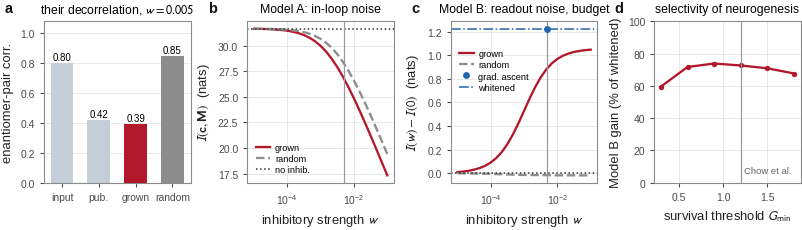

In [15]:
mean = lambda k: ch_sw[k].mean(0)

# Plot data is dumped so the layout can be retuned without rerunning the notebook.
np.savez_compressed(os.path.join(OUTDIR, "figdata_fig4.npz"),
                    CH_WS=CH_WS, IA_a=mean("IA_a"), IA_r=mean("IA_r"),
                    IB_a=mean("IB_a"), IB_r=mean("IB_r"), ch_Iff=ch_Iff,
                    ch_avail=ch_avail, ch_gain_grad=ch_gain_g.mean(), CH_W=CH_W,
                    top=np.array([ch_top[k] for k in ("input", "published", "grown", "random")]),
                    gmins=np.array(CH_GMINS), gfrac=ch_gfrac)

def draw_fig4(W=WIDE_W, H=WIDE_H, name="Fig5_chow_network"):
    """One row of four panels, sized for the full text width plus the left margin."""
    fig, axes = plt.subplots(1, 4, figsize=(W, H))
    ax = axes.ravel()

    # (a) Chow et al.'s decorrelation measure
    labs = ["input", "pub.", "grown", "random"]
    vals = [ch_top[k] for k in ("input", "published", "grown", "random")]
    ax[0].bar(range(4), vals, color=[C_FAINT, C_FAINT, C_TARGET, C_CTRL], width=0.62)
    for i, v in enumerate(vals):
        ax[0].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=6.4)
    ax[0].set_xticks(range(4), labs, fontsize=6.8)
    ax[0].set_ylim(0, 1.08); ax[0].grid(axis="x", visible=False)
    ax[0].set_ylabel("enantiomer-pair corr.")
    ax[0].set_title(f"their decorrelation, $w={CH_W}$", fontsize=8.0)

    # (b) Model A
    ax[1].plot(CH_WS[1:], mean("IA_a")[1:], color=C_TARGET, label="grown")
    ax[1].plot(CH_WS[1:], mean("IA_r")[1:], color=C_CTRL, ls="--", label="random")
    ax[1].axhline(mean("IA_a")[0], color=C_INK, ls=":", lw=1.0, label="no inhib.")
    ax[1].axvline(CH_W, color="#9a9a9a", lw=0.8)
    ax[1].set_xscale("log"); ax[1].set_xlabel("inhibitory strength $w$")
    ax[1].set_ylabel("$I(\\mathbf{c},\\mathbf{M})$  (nats)")
    ax[1].set_title("Model A: in-loop noise", fontsize=8.0)
    ax[1].legend(loc="lower left", fontsize=6.0, labelspacing=0.25)

    # (c) Model B, with the gradient-ascent result at their operating point
    ax[2].plot(CH_WS[1:], mean("IB_a")[1:] - ch_Iff, color=C_TARGET, label="grown")
    ax[2].plot(CH_WS[1:], mean("IB_r")[1:] - ch_Iff, color=C_CTRL, ls="--", label="random")
    ax[2].plot([CH_W], [ch_gain_g.mean()], "o", color=C_MAIN, ms=4.5, zorder=5,
               label="grad. ascent")
    ax[2].axhline(ch_avail, color=C_MAIN, ls="-.", lw=1.0, label="whitened")
    ax[2].axhline(0.0, color=C_INK, ls=":", lw=1.0)
    ax[2].axvline(CH_W, color="#9a9a9a", lw=0.8)
    ax[2].set_xscale("log"); ax[2].set_xlabel("inhibitory strength $w$")
    ax[2].set_ylabel("$I(w)-I(0)$  (nats)")
    ax[2].set_title("Model B: readout noise, budget", fontsize=8.0)
    ax[2].legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=6.0,
               labelspacing=0.25)

    # (d) survival threshold
    ax[3].plot(np.array(CH_GMINS), ch_gfrac, "o-", color=C_TARGET, ms=3.5)
    ax[3].axvline(1.2, color="#9a9a9a", lw=0.8)
    ax[3].text(1.23, 6, "Chow et al.", fontsize=6.2, color="#666666")
    ax[3].set_ylim(0, 100)
    ax[3].set_xlabel("survival threshold $G_{\\min}$")
    ax[3].set_ylabel("Model B gain (% of whitened)")
    ax[3].set_title("selectivity of neurogenesis", fontsize=8.0)

    for axx in ax:
        axx.tick_params(labelsize=6.8)
    panels(axes, dx=-26, dy=4)
    fig.tight_layout(w_pad=0.9)
    save(fig, name)
    return fig

fig = draw_fig4()
plt.show()

## 10. Manifest and audit dump

In [16]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, sort_keys=True)

expected = ["Fig1_framework", "Fig2_two_noise_models", "Fig3_flatness",
            "Fig4_gradient_ascent", "Fig5_chow_network"]
print("figure manifest")
print("=" * 52)
for name in expected:
    p = os.path.join(OUTDIR, name + ".pdf")
    print(f"  {'OK ' if os.path.exists(p) else 'MISSING'}  {p}"
          f"{'' if not os.path.exists(p) else f'   {os.path.getsize(p)/1024:.0f} kB'}")
print()
n_compared = sum(1 for c in CHECKS if c[3] is not None)
record("n_checks", n_compared)
record("n_recorded", len(RESULTS))
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, sort_keys=True)
print(f"{len(RESULTS)} quantities recorded -> results.json")
print(f"{n_compared} of them compared against the value printed in the manuscript")
if FAILURES:
    print("\nFAILED CHECKS:")
    for f_ in FAILURES:
        print("  " + f_)
    raise AssertionError(f"{len(FAILURES)} check(s) disagree with the manuscript")
print("\nAll checks agree with the values printed in the manuscript.")
print("\nEvery number quoted in the manuscript, including its appendix, appears")
print("above beside its computed value.")

figure manifest
  OK   figures/Fig1_framework.pdf   52 kB
  OK   figures/Fig2_two_noise_models.pdf   40 kB
  OK   figures/Fig3_flatness.pdf   53 kB
  OK   figures/Fig4_gradient_ascent.pdf   54 kB
  OK   figures/Fig5_chow_network.pdf   33 kB

182 quantities recorded -> results.json
50 of them compared against the value printed in the manuscript

All checks agree with the values printed in the manuscript.

Every number quoted in the manuscript, including its appendix, appears
above beside its computed value.
